In [1]:
# Basic tools for the isolated dynamics

from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

from numba import njit
from scipy.stats import t as student_t

from matplotlib.animation import FuncAnimation, PillowWriter

from hp_core import (
    hp_jacobian,
    rk4_step,
    rk4_tangent_matrix_step,
    gram_schmidt
)

In [2]:
# Output folders

data_dir = Path("data")
figures_dir = Path("figures")

data_dir.mkdir(
    exist_ok=True
)

figures_dir.mkdir(
    exist_ok=True
)

In [3]:
# Hastings-Powell parameters

a1 = 5.0
a2 = 0.1
b1 = 3.0
b2 = 2.0
d2 = 0.01


# Main point and robustness point

d1_040 = 0.40
d1_038 = 0.38


parameters_040 = np.array([
    a1,
    a2,
    b1,
    b2,
    d1_040,
    d2
])

parameters_038 = np.array([
    a1,
    a2,
    b1,
    b2,
    d1_038,
    d2
])


# Keep the same reference initial condition in both cases

initial_state = np.array([
    1.0,
    1.0,
    1.0
])

In [4]:
# Main integration settings

dt = 0.01

transient_time = 20000.0
trajectory_time = 200000.0


# Keep every RK4 step after the transient

trajectory_start_time = transient_time

trajectory_end_time = (
    transient_time
    + trajectory_time
)


# Store the full trajectories in binary files

trajectory_file_040 = (
    data_dir
    / "hp_d1_040_full_trajectory.npy"
)

trajectory_file_038 = (
    data_dir
    / "hp_d1_038_full_trajectory.npy"
)

In [5]:
# Lyapunov protocol

alignment_time = 5000.0
average_time = 200000.0

renormalization_time = 1.0
block_time = 2500.0


# Keep the Lyapunov run independent from the stored trajectory

lyapunov_initial_state = initial_state.copy()

In [6]:
# Nearby trajectories for the sensitivity test

perturbation_size = 1.0e-8
sensitivity_time = 3000.0


# Use local time from the moment the perturbation is applied

sensitivity_dt = dt

In [7]:
# Representative window for the static figures

plot_start_time = transient_time
plot_time = 1500.0

plot_end_time = (
    plot_start_time
    + plot_time
)

In [8]:
# Animation window

animation_start_time = transient_time
animation_time = 1500.0

animation_end_time = (
    animation_start_time
    + animation_time
)


# Every integration point remains in the animated trajectory

animation_points_per_frame = 500
animation_fps = 20


# Save GIF files with Pillow, without FFmpeg

animation_file_040 = (
    figures_dir
    / "hp_d1_040_dynamics.gif"
)

animation_file_038 = (
    figures_dir
    / "hp_d1_038_dynamics.gif"
)

In [9]:
# Full-resolution trajectory written directly to disk

@njit
def fill_full_trajectory(
    parameters,
    initial_state,
    dt,
    transient_steps,
    trajectory
):

    state = initial_state.copy()


    # Remove the transient before storing the attractor dynamics

    for _ in range(transient_steps):

        state = rk4_step(
            state,
            parameters,
            dt
        )


    # The first stored state is at t = transient_time

    trajectory[0] = state


    # Keep every RK4 step after the transient

    for i in range(
        1,
        trajectory.shape[0]
    ):

        state = rk4_step(
            state,
            parameters,
            dt
        )

        trajectory[i] = state


    return state


def save_full_trajectory(
    parameters,
    initial_state,
    dt,
    transient_time,
    trajectory_time,
    filename
):

    transient_steps = int(
        round(
            transient_time / dt
        )
    )

    trajectory_steps = int(
        round(
            trajectory_time / dt
        )
    )


    # Include both ends of the stored time interval

    n_points = (
        trajectory_steps
        + 1
    )


    # Create a valid .npy file without loading it all into RAM

    trajectory = np.lib.format.open_memmap(
        filename,
        mode="w+",
        dtype=np.float64,
        shape=(n_points, 3)
    )


    final_state = fill_full_trajectory(
        parameters,
        initial_state,
        dt,
        transient_steps,
        trajectory
    )


    # Make sure all buffered data are written to disk

    trajectory.flush()


    return (
        final_state,
        n_points
    )

In [10]:
# Full trajectory at d1 = 0.40

expected_points = (
    int(
        round(
            trajectory_time / dt
        )
    )
    + 1
)


print(
    "Expected stored points:",
    expected_points
)

print(
    "Stored time interval:",
    trajectory_start_time,
    "to",
    trajectory_end_time
)


final_state_040, n_points_040 = save_full_trajectory(
    parameters_040,
    initial_state,
    dt,
    transient_time,
    trajectory_time,
    trajectory_file_040
)


# Reopen the trajectory without loading the full file into RAM

trajectory_040 = np.load(
    trajectory_file_040,
    mmap_mode="r"
)


print()
print("d1 = 0.40")
print("trajectory shape:", trajectory_040.shape)
print("stored points:", n_points_040)
print("dtype:", trajectory_040.dtype)

print(
    "file size:",
    f"{trajectory_file_040.stat().st_size / 1024**2:.2f} MiB"
)

print(
    "first stored state:",
    trajectory_040[0]
)

print(
    "final stored state:",
    trajectory_040[-1]
)

print(
    "final state returned:",
    final_state_040
)

Expected stored points: 20000001
Stored time interval: 20000.0 to 220000.0

d1 = 0.40
trajectory shape: (20000001, 3)
stored points: 20000001
dtype: float64
file size: 457.76 MiB
first stored state: [0.77221097 0.19819987 7.525581  ]
final stored state: [ 0.79497424  0.13073953 10.29647258]
final state returned: [ 0.79497424  0.13073953 10.29647258]


In [11]:
# Full trajectory at d1 = 0.38

print(
    "Expected stored points:",
    expected_points
)

print(
    "Stored time interval:",
    trajectory_start_time,
    "to",
    trajectory_end_time
)


final_state_038, n_points_038 = save_full_trajectory(
    parameters_038,
    initial_state,
    dt,
    transient_time,
    trajectory_time,
    trajectory_file_038
)


# Reopen the trajectory without loading the full file into RAM

trajectory_038 = np.load(
    trajectory_file_038,
    mmap_mode="r"
)


print()
print("d1 = 0.38")
print("trajectory shape:", trajectory_038.shape)
print("stored points:", n_points_038)
print("dtype:", trajectory_038.dtype)

print(
    "file size:",
    f"{trajectory_file_038.stat().st_size / 1024**2:.2f} MiB"
)

print(
    "first stored state:",
    trajectory_038[0]
)

print(
    "final stored state:",
    trajectory_038[-1]
)

print(
    "final state returned:",
    final_state_038
)

Expected stored points: 20000001
Stored time interval: 20000.0 to 220000.0

d1 = 0.38
trajectory shape: (20000001, 3)
stored points: 20000001
dtype: float64
file size: 457.76 MiB
first stored state: [0.41076173 0.10791395 8.81300422]
final stored state: [0.76380202 0.10401688 8.98174007]
final state returned: [0.76380202 0.10401688 8.98174007]


In [12]:
# Extract the representative post-transient window

plot_start_index = int(
    round(
        (plot_start_time - trajectory_start_time) / dt
    )
)

plot_end_index = (
    int(
        round(
            (plot_end_time - trajectory_start_time) / dt
        )
    )
    + 1
)


# Rebuild the absolute simulation time only for this window

plot_times = (
    trajectory_start_time
    + np.arange(
        plot_start_index,
        plot_end_index
    ) * dt
)


# Read only the points needed for the figures

plot_trajectory_040 = trajectory_040[
    plot_start_index:plot_end_index
]

plot_trajectory_038 = trajectory_038[
    plot_start_index:plot_end_index
]


print(
    "Plot time interval:",
    plot_times[0],
    "to",
    plot_times[-1]
)

print(
    "Points in the window:",
    len(plot_times)
)

print(
    "d1 = 0.40 shape:",
    plot_trajectory_040.shape
)

print(
    "d1 = 0.38 shape:",
    plot_trajectory_038.shape
)

Plot time interval: 20000.0 to 21500.0
Points in the window: 150001
d1 = 0.40 shape: (150001, 3)
d1 = 0.38 shape: (150001, 3)


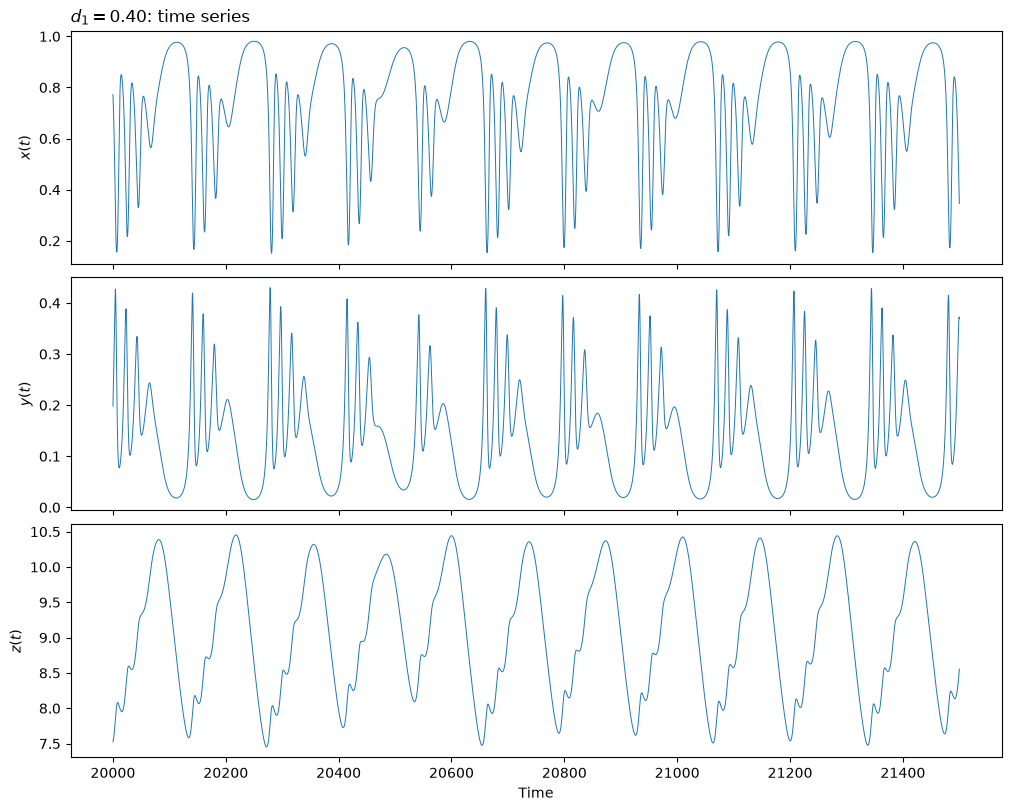

In [13]:
# Time series at d1 = 0.40

fig, axes = plt.subplots(
    3,
    1,
    figsize=(10, 8),
    sharex=True,
    constrained_layout=True
)


# Use the full post-transient window

axes[0].plot(
    plot_times,
    plot_trajectory_040[:, 0],
    linewidth=0.7
)

axes[1].plot(
    plot_times,
    plot_trajectory_040[:, 1],
    linewidth=0.7
)

axes[2].plot(
    plot_times,
    plot_trajectory_040[:, 2],
    linewidth=0.7
)


axes[0].set_ylabel(
    r"$x(t)$"
)

axes[1].set_ylabel(
    r"$y(t)$"
)

axes[2].set_ylabel(
    r"$z(t)$"
)

axes[2].set_xlabel(
    "Time"
)


axes[0].set_title(
    r"$d_1 = 0.40$: time series",
    loc="left"
)


fig.savefig(
    figures_dir
    / "hp_d1_040_time_series.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    figures_dir
    / "hp_d1_040_time_series.pdf",
    bbox_inches="tight"
)


plt.show()

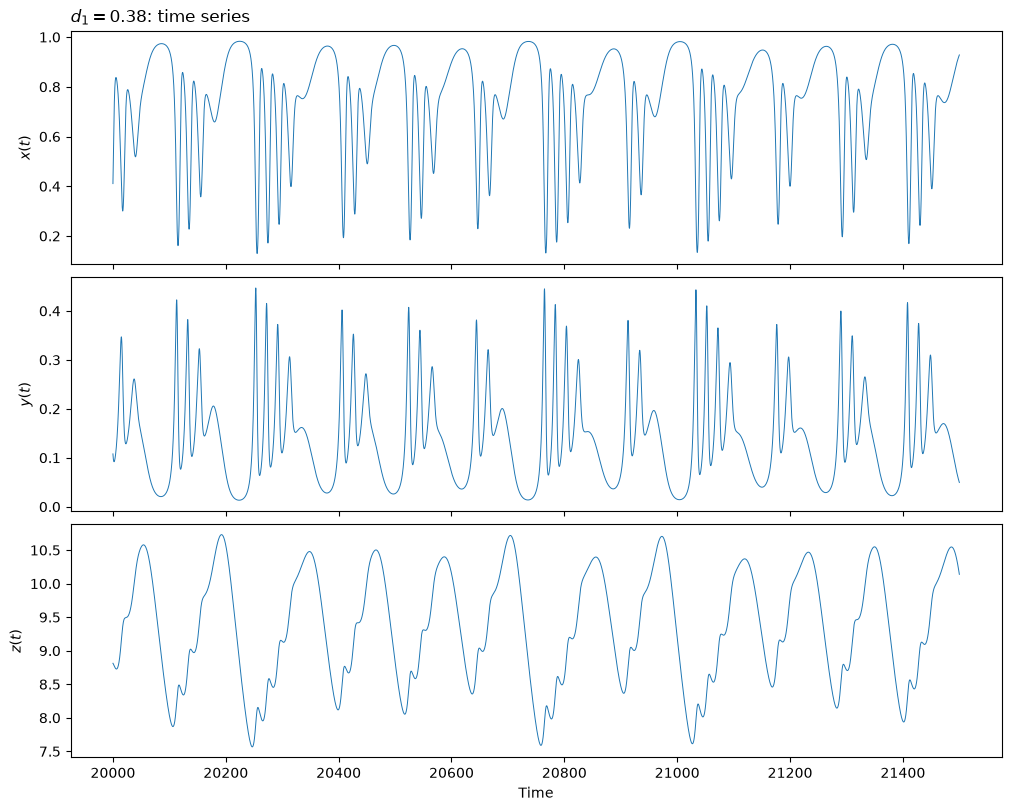

In [14]:
# Time series at d1 = 0.38

fig, axes = plt.subplots(
    3,
    1,
    figsize=(10, 8),
    sharex=True,
    constrained_layout=True
)


# Use the full post-transient window

axes[0].plot(
    plot_times,
    plot_trajectory_038[:, 0],
    linewidth=0.7
)

axes[1].plot(
    plot_times,
    plot_trajectory_038[:, 1],
    linewidth=0.7
)

axes[2].plot(
    plot_times,
    plot_trajectory_038[:, 2],
    linewidth=0.7
)


axes[0].set_ylabel(
    r"$x(t)$"
)

axes[1].set_ylabel(
    r"$y(t)$"
)

axes[2].set_ylabel(
    r"$z(t)$"
)

axes[2].set_xlabel(
    "Time"
)


axes[0].set_title(
    r"$d_1 = 0.38$: time series",
    loc="left"
)


fig.savefig(
    figures_dir
    / "hp_d1_038_time_series.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    figures_dir
    / "hp_d1_038_time_series.pdf",
    bbox_inches="tight"
)


plt.show()

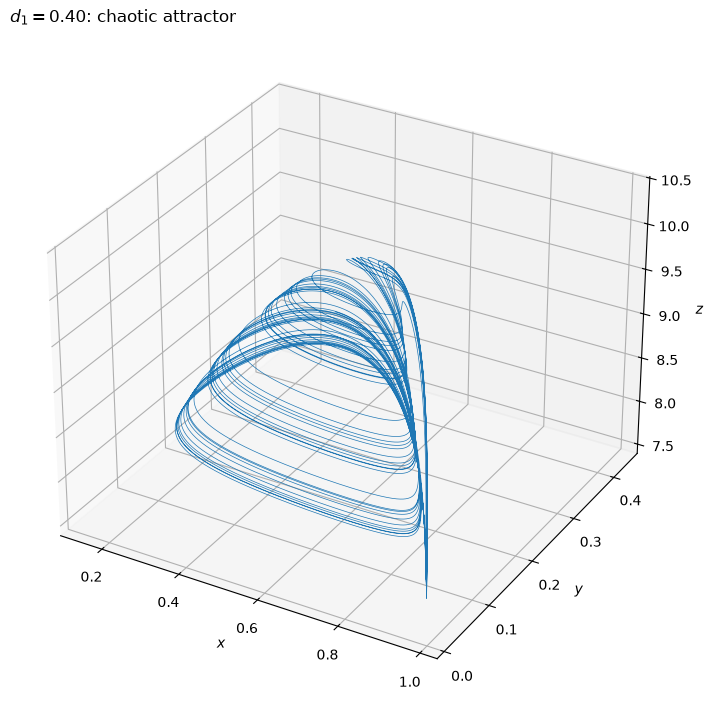

In [15]:
# 3D attractor at d1 = 0.40

fig = plt.figure(
    figsize=(8, 7),
    constrained_layout=True
)

ax = fig.add_subplot(
    111,
    projection="3d"
)


# Use the same post-transient window as the time series

ax.plot(
    plot_trajectory_040[:, 0],
    plot_trajectory_040[:, 1],
    plot_trajectory_040[:, 2],
    linewidth=0.5
)


ax.set_xlabel(
    r"$x$"
)

ax.set_ylabel(
    r"$y$"
)

ax.set_zlabel(
    r"$z$"
)

ax.set_title(
    r"$d_1 = 0.40$: chaotic attractor",
    loc="left"
)


fig.savefig(
    figures_dir
    / "hp_d1_040_attractor_3d.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    figures_dir
    / "hp_d1_040_attractor_3d.pdf",
    bbox_inches="tight"
)


plt.show()

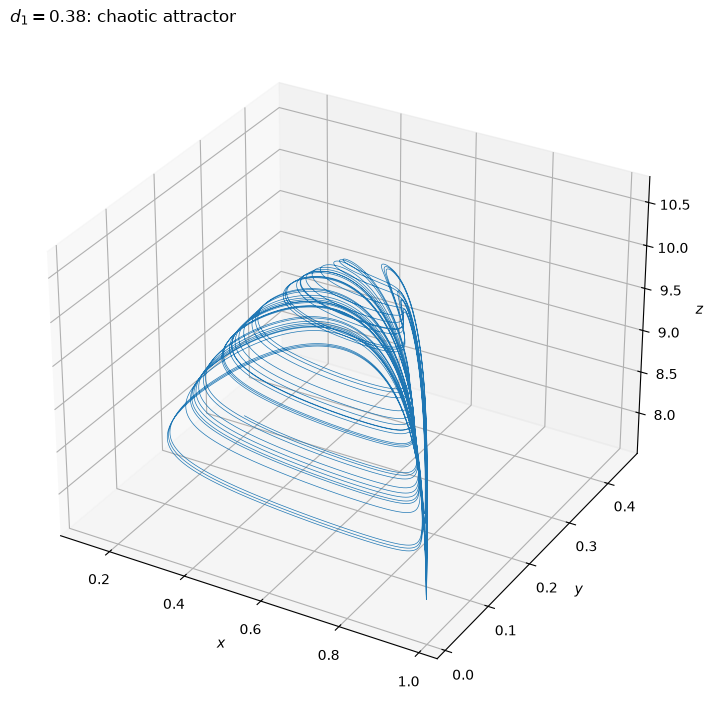

In [16]:
# 3D attractor at d1 = 0.38

fig = plt.figure(
    figsize=(8, 7),
    constrained_layout=True
)

ax = fig.add_subplot(
    111,
    projection="3d"
)


# Use the same post-transient window as the time series

ax.plot(
    plot_trajectory_038[:, 0],
    plot_trajectory_038[:, 1],
    plot_trajectory_038[:, 2],
    linewidth=0.5
)


ax.set_xlabel(
    r"$x$"
)

ax.set_ylabel(
    r"$y$"
)

ax.set_zlabel(
    r"$z$"
)

ax.set_title(
    r"$d_1 = 0.38$: chaotic attractor",
    loc="left"
)


fig.savefig(
    figures_dir
    / "hp_d1_038_attractor_3d.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    figures_dir
    / "hp_d1_038_attractor_3d.pdf",
    bbox_inches="tight"
)


plt.show()

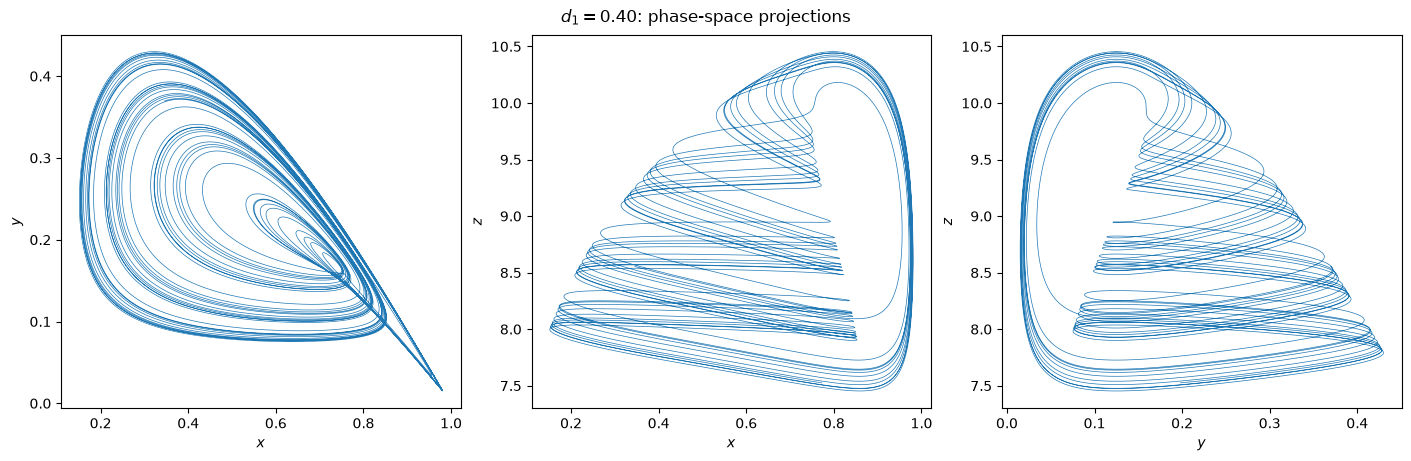

In [17]:
# Phase-space projections at d1 = 0.40

fig, axes = plt.subplots(
    1,
    3,
    figsize=(14, 4.5),
    constrained_layout=True
)


# Use the same post-transient window as the attractor

axes[0].plot(
    plot_trajectory_040[:, 0],
    plot_trajectory_040[:, 1],
    linewidth=0.5
)

axes[1].plot(
    plot_trajectory_040[:, 0],
    plot_trajectory_040[:, 2],
    linewidth=0.5
)

axes[2].plot(
    plot_trajectory_040[:, 1],
    plot_trajectory_040[:, 2],
    linewidth=0.5
)


axes[0].set_xlabel(
    r"$x$"
)

axes[0].set_ylabel(
    r"$y$"
)


axes[1].set_xlabel(
    r"$x$"
)

axes[1].set_ylabel(
    r"$z$"
)


axes[2].set_xlabel(
    r"$y$"
)

axes[2].set_ylabel(
    r"$z$"
)


fig.suptitle(
    r"$d_1 = 0.40$: phase-space projections"
)


fig.savefig(
    figures_dir
    / "hp_d1_040_projections.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    figures_dir
    / "hp_d1_040_projections.pdf",
    bbox_inches="tight"
)


plt.show()

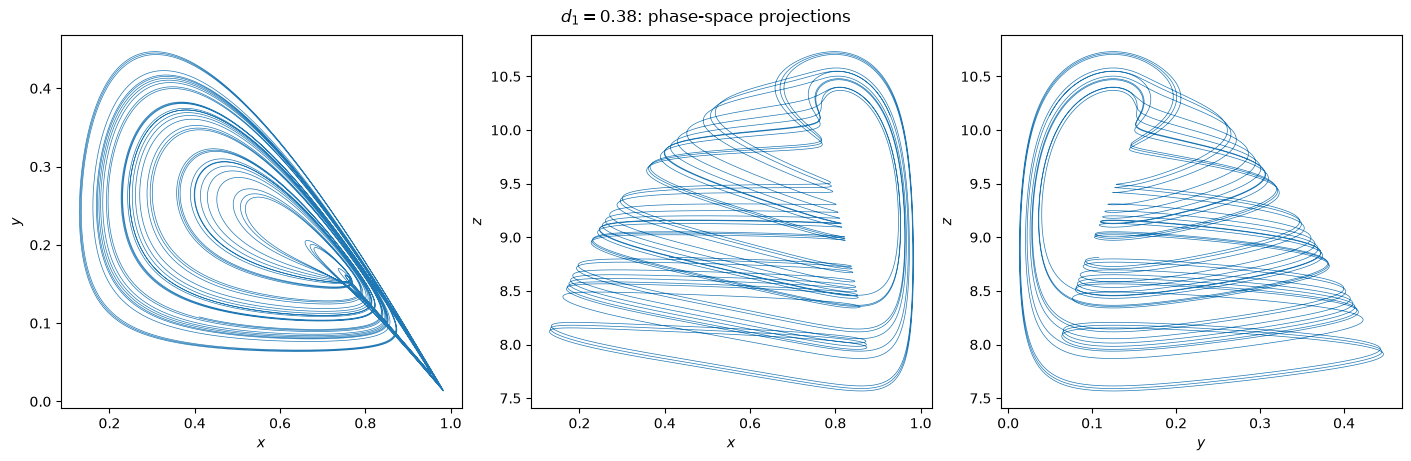

In [18]:
# Phase-space projections at d1 = 0.38

fig, axes = plt.subplots(
    1,
    3,
    figsize=(14, 4.5),
    constrained_layout=True
)


# Use the same post-transient window as the attractor

axes[0].plot(
    plot_trajectory_038[:, 0],
    plot_trajectory_038[:, 1],
    linewidth=0.5
)

axes[1].plot(
    plot_trajectory_038[:, 0],
    plot_trajectory_038[:, 2],
    linewidth=0.5
)

axes[2].plot(
    plot_trajectory_038[:, 1],
    plot_trajectory_038[:, 2],
    linewidth=0.5
)


axes[0].set_xlabel(
    r"$x$"
)

axes[0].set_ylabel(
    r"$y$"
)


axes[1].set_xlabel(
    r"$x$"
)

axes[1].set_ylabel(
    r"$z$"
)


axes[2].set_xlabel(
    r"$y$"
)

axes[2].set_ylabel(
    r"$z$"
)


fig.suptitle(
    r"$d_1 = 0.38$: phase-space projections"
)


fig.savefig(
    figures_dir
    / "hp_d1_038_projections.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    figures_dir
    / "hp_d1_038_projections.pdf",
    bbox_inches="tight"
)


plt.show()

In [19]:
# Nearby trajectories for the sensitivity test

@njit
def nearby_trajectories(
    parameters,
    reference_state,
    dt,
    sensitivity_time,
    perturbation_size
):

    state_a = reference_state.copy()
    state_b = reference_state.copy()


    # Perturb only x at the start of the experiment

    state_b[0] += perturbation_size


    n_steps = int(
        round(
            sensitivity_time / dt
        )
    )

    n_points = (
        n_steps
        + 1
    )


    # Local time starts when the perturbation is applied

    times = np.arange(
        n_points
    ) * dt


    trajectory_a = np.empty(
        (n_points, 3)
    )

    trajectory_b = np.empty(
        (n_points, 3)
    )

    separation = np.empty(
        n_points
    )


    trajectory_a[0] = state_a
    trajectory_b[0] = state_b

    separation[0] = np.linalg.norm(
        state_b
        - state_a
    )


    # Integrate both trajectories with the same RK4 step

    for i in range(
        1,
        n_points
    ):

        state_a = rk4_step(
            state_a,
            parameters,
            dt
        )

        state_b = rk4_step(
            state_b,
            parameters,
            dt
        )

        trajectory_a[i] = state_a
        trajectory_b[i] = state_b

        separation[i] = np.linalg.norm(
            state_b
            - state_a
        )


    return (
        times,
        trajectory_a,
        trajectory_b,
        separation
    )

In [20]:
# Sensitivity test at d1 = 0.40

reference_state_040 = np.array(
    trajectory_040[0]
)


# This state is already on the post-transient trajectory

(
    sensitivity_times_040,
    sensitivity_reference_040,
    sensitivity_perturbed_040,
    separation_040
) = nearby_trajectories(
    parameters_040,
    reference_state_040,
    sensitivity_dt,
    sensitivity_time,
    perturbation_size
)


print(
    "Reference state:",
    reference_state_040
)

print(
    "Sensitivity points:",
    len(sensitivity_times_040)
)

print(
    "Time interval:",
    sensitivity_times_040[0],
    "to",
    sensitivity_times_040[-1]
)

print(
    "Initial separation:",
    separation_040[0]
)

print(
    "Maximum separation:",
    np.max(separation_040)
)

print(
    "Final separation:",
    separation_040[-1]
)

Reference state: [0.77221097 0.19819987 7.525581  ]
Sensitivity points: 300001
Time interval: 0.0 to 3000.0
Initial separation: 1.0000000050247593e-08
Maximum separation: 1.6583225587254744
Final separation: 1.1956987690642022


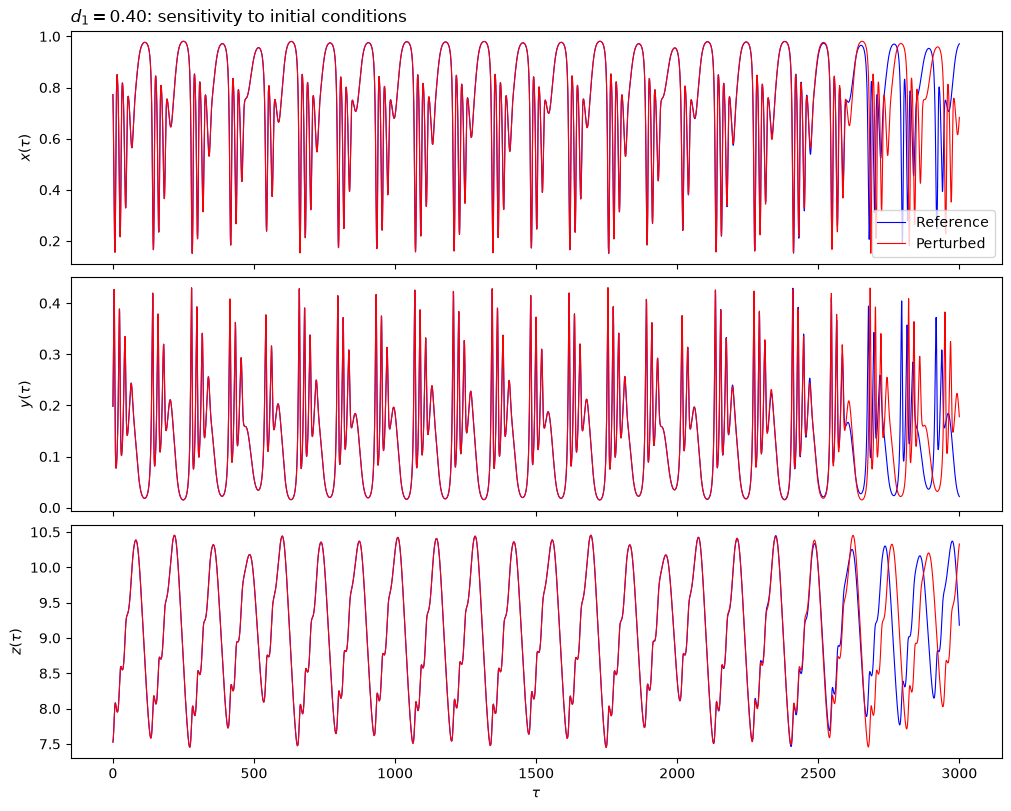

In [21]:
# Nearby time series at d1 = 0.40

fig, axes = plt.subplots(
    3,
    1,
    figsize=(10, 8),
    sharex=True,
    constrained_layout=True
)


# Blue: reference trajectory
# Red: infinitesimally perturbed trajectory

axes[0].plot(
    sensitivity_times_040,
    sensitivity_reference_040[:, 0],
    color="blue",
    linewidth=0.8,
    label="Reference"
)

axes[0].plot(
    sensitivity_times_040,
    sensitivity_perturbed_040[:, 0],
    color="red",
    linewidth=0.8,
    label="Perturbed"
)


axes[1].plot(
    sensitivity_times_040,
    sensitivity_reference_040[:, 1],
    color="blue",
    linewidth=0.8
)

axes[1].plot(
    sensitivity_times_040,
    sensitivity_perturbed_040[:, 1],
    color="red",
    linewidth=0.8
)


axes[2].plot(
    sensitivity_times_040,
    sensitivity_reference_040[:, 2],
    color="blue",
    linewidth=0.8
)

axes[2].plot(
    sensitivity_times_040,
    sensitivity_perturbed_040[:, 2],
    color="red",
    linewidth=0.8
)


axes[0].set_ylabel(
    r"$x(\tau)$"
)

axes[1].set_ylabel(
    r"$y(\tau)$"
)

axes[2].set_ylabel(
    r"$z(\tau)$"
)

axes[2].set_xlabel(
    r"$\tau$"
)


axes[0].set_title(
    r"$d_1 = 0.40$: sensitivity to initial conditions",
    loc="left"
)

axes[0].legend()


fig.savefig(
    figures_dir
    / "hp_d1_040_sensitivity_time_series.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    figures_dir
    / "hp_d1_040_sensitivity_time_series.pdf",
    bbox_inches="tight"
)


plt.show()

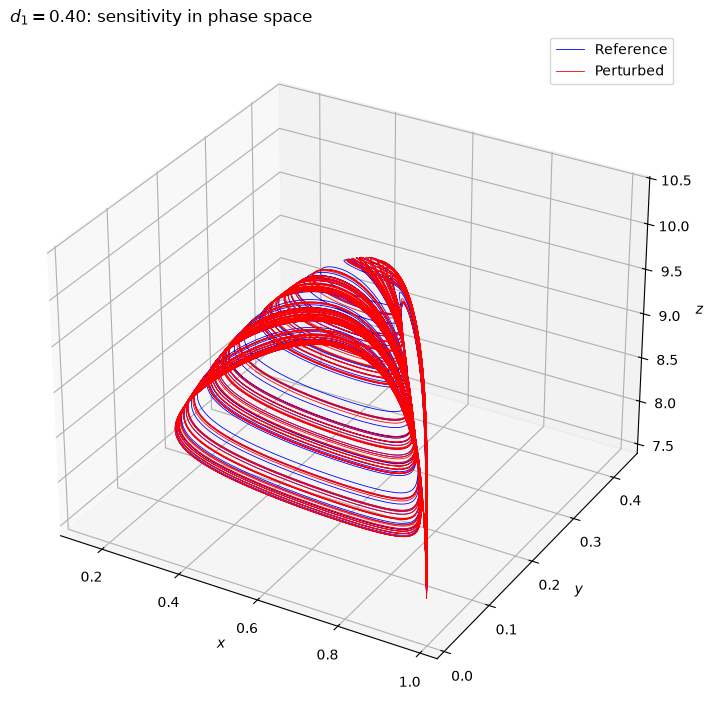

In [22]:
# Nearby trajectories in phase space at d1 = 0.40

fig = plt.figure(
    figsize=(8, 7),
    constrained_layout=True
)

ax = fig.add_subplot(
    111,
    projection="3d"
)


# Blue: reference trajectory
# Red: infinitesimally perturbed trajectory

ax.plot(
    sensitivity_reference_040[:, 0],
    sensitivity_reference_040[:, 1],
    sensitivity_reference_040[:, 2],
    color="blue",
    linewidth=0.6,
    label="Reference"
)

ax.plot(
    sensitivity_perturbed_040[:, 0],
    sensitivity_perturbed_040[:, 1],
    sensitivity_perturbed_040[:, 2],
    color="red",
    linewidth=0.6,
    label="Perturbed"
)


ax.set_xlabel(
    r"$x$"
)

ax.set_ylabel(
    r"$y$"
)

ax.set_zlabel(
    r"$z$"
)

ax.set_title(
    r"$d_1 = 0.40$: sensitivity in phase space",
    loc="left"
)

ax.legend()


fig.savefig(
    figures_dir
    / "hp_d1_040_sensitivity_attractor_3d.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    figures_dir
    / "hp_d1_040_sensitivity_attractor_3d.pdf",
    bbox_inches="tight"
)


plt.show()

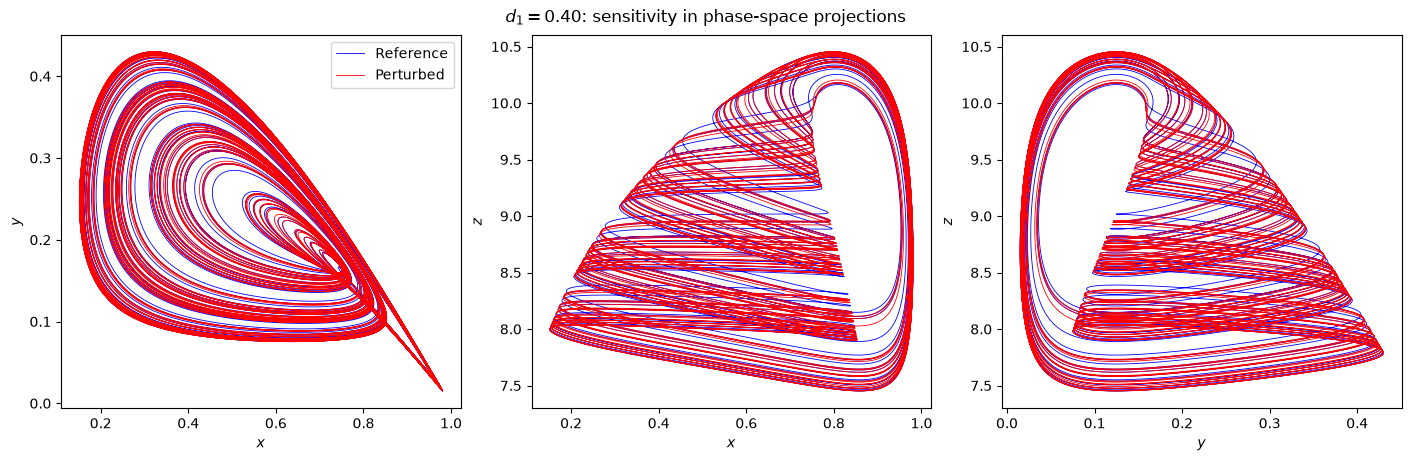

In [23]:
# Nearby trajectories in phase-space projections at d1 = 0.40

fig, axes = plt.subplots(
    1,
    3,
    figsize=(14, 4.5),
    constrained_layout=True
)


# Blue: reference trajectory
# Red: infinitesimally perturbed trajectory

axes[0].plot(
    sensitivity_reference_040[:, 0],
    sensitivity_reference_040[:, 1],
    color="blue",
    linewidth=0.6,
    label="Reference"
)

axes[0].plot(
    sensitivity_perturbed_040[:, 0],
    sensitivity_perturbed_040[:, 1],
    color="red",
    linewidth=0.6,
    label="Perturbed"
)


axes[1].plot(
    sensitivity_reference_040[:, 0],
    sensitivity_reference_040[:, 2],
    color="blue",
    linewidth=0.6
)

axes[1].plot(
    sensitivity_perturbed_040[:, 0],
    sensitivity_perturbed_040[:, 2],
    color="red",
    linewidth=0.6
)


axes[2].plot(
    sensitivity_reference_040[:, 1],
    sensitivity_reference_040[:, 2],
    color="blue",
    linewidth=0.6
)

axes[2].plot(
    sensitivity_perturbed_040[:, 1],
    sensitivity_perturbed_040[:, 2],
    color="red",
    linewidth=0.6
)


axes[0].set_xlabel(
    r"$x$"
)

axes[0].set_ylabel(
    r"$y$"
)


axes[1].set_xlabel(
    r"$x$"
)

axes[1].set_ylabel(
    r"$z$"
)


axes[2].set_xlabel(
    r"$y$"
)

axes[2].set_ylabel(
    r"$z$"
)


axes[0].legend()


fig.suptitle(
    r"$d_1 = 0.40$: sensitivity in phase-space projections"
)


fig.savefig(
    figures_dir
    / "hp_d1_040_sensitivity_projections.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    figures_dir
    / "hp_d1_040_sensitivity_projections.pdf",
    bbox_inches="tight"
)


plt.show()

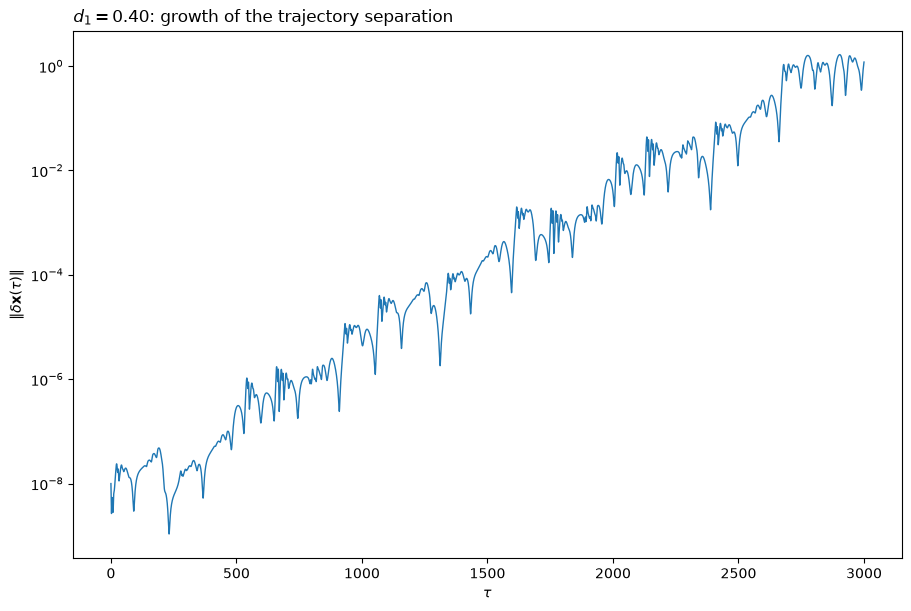

In [24]:
# Logarithmic separation at d1 = 0.40

fig, ax = plt.subplots(
    figsize=(9, 6),
    constrained_layout=True
)


ax.semilogy(
    sensitivity_times_040,
    separation_040,
    linewidth=1.0
)


ax.set_xlabel(
    r"$\tau$"
)

ax.set_ylabel(
    r"$\|\delta \mathbf{x}(\tau)\|$"
)

ax.set_title(
    r"$d_1 = 0.40$: growth of the trajectory separation",
    loc="left"
)


fig.savefig(
    figures_dir
    / "hp_d1_040_sensitivity_separation.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    figures_dir
    / "hp_d1_040_sensitivity_separation.pdf",
    bbox_inches="tight"
)


plt.show()

In [25]:
# Sensitivity test at d1 = 0.38

reference_state_038 = np.array(
    trajectory_038[0]
)


# This state is already on the post-transient trajectory

(
    sensitivity_times_038,
    sensitivity_reference_038,
    sensitivity_perturbed_038,
    separation_038
) = nearby_trajectories(
    parameters_038,
    reference_state_038,
    sensitivity_dt,
    sensitivity_time,
    perturbation_size
)


print(
    "Reference state:",
    reference_state_038
)

print(
    "Sensitivity points:",
    len(sensitivity_times_038)
)

print(
    "Time interval:",
    sensitivity_times_038[0],
    "to",
    sensitivity_times_038[-1]
)

print(
    "Initial separation:",
    separation_038[0]
)

print(
    "Maximum separation:",
    np.max(separation_038)
)

print(
    "Final separation:",
    separation_038[-1]
)

Reference state: [0.41076173 0.10791395 8.81300422]
Sensitivity points: 300001
Time interval: 0.0 to 3000.0
Initial separation: 9.999999994736442e-09
Maximum separation: 2.6720495647319065
Final separation: 1.4429561150811


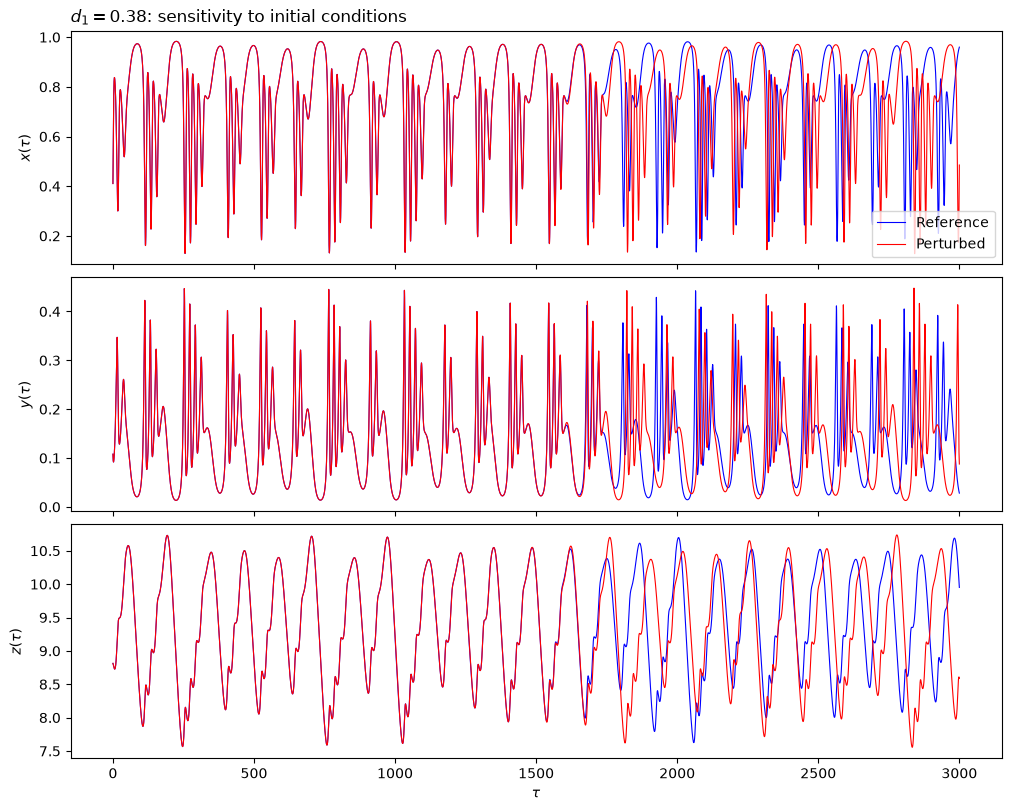

In [26]:
# Nearby time series at d1 = 0.38

fig, axes = plt.subplots(
    3,
    1,
    figsize=(10, 8),
    sharex=True,
    constrained_layout=True
)


# Blue: reference trajectory
# Red: infinitesimally perturbed trajectory

axes[0].plot(
    sensitivity_times_038,
    sensitivity_reference_038[:, 0],
    color="blue",
    linewidth=0.8,
    label="Reference"
)

axes[0].plot(
    sensitivity_times_038,
    sensitivity_perturbed_038[:, 0],
    color="red",
    linewidth=0.8,
    label="Perturbed"
)


axes[1].plot(
    sensitivity_times_038,
    sensitivity_reference_038[:, 1],
    color="blue",
    linewidth=0.8
)

axes[1].plot(
    sensitivity_times_038,
    sensitivity_perturbed_038[:, 1],
    color="red",
    linewidth=0.8
)


axes[2].plot(
    sensitivity_times_038,
    sensitivity_reference_038[:, 2],
    color="blue",
    linewidth=0.8
)

axes[2].plot(
    sensitivity_times_038,
    sensitivity_perturbed_038[:, 2],
    color="red",
    linewidth=0.8
)


axes[0].set_ylabel(
    r"$x(\tau)$"
)

axes[1].set_ylabel(
    r"$y(\tau)$"
)

axes[2].set_ylabel(
    r"$z(\tau)$"
)

axes[2].set_xlabel(
    r"$\tau$"
)


axes[0].set_title(
    r"$d_1 = 0.38$: sensitivity to initial conditions",
    loc="left"
)

axes[0].legend()


fig.savefig(
    figures_dir
    / "hp_d1_038_sensitivity_time_series.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    figures_dir
    / "hp_d1_038_sensitivity_time_series.pdf",
    bbox_inches="tight"
)


plt.show()

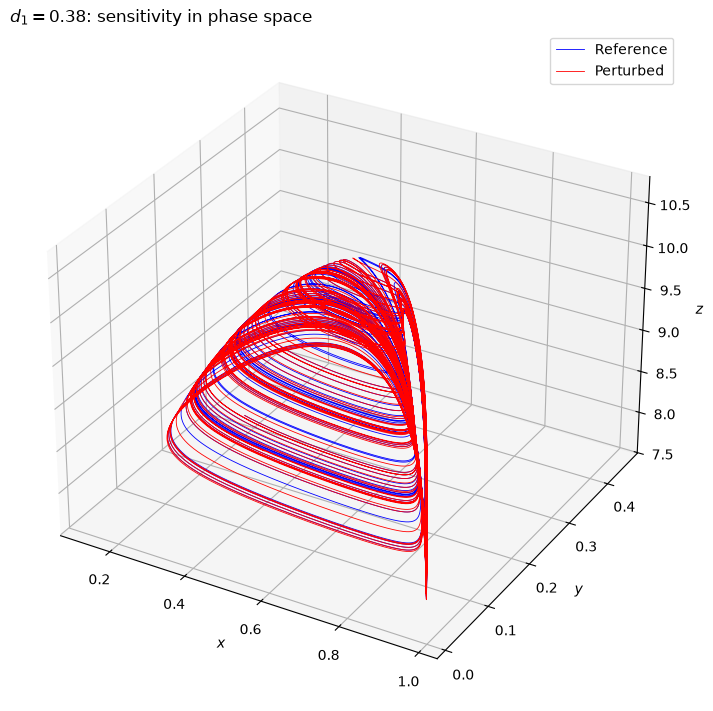

In [27]:
# Nearby trajectories in phase space at d1 = 0.38

fig = plt.figure(
    figsize=(8, 7),
    constrained_layout=True
)

ax = fig.add_subplot(
    111,
    projection="3d"
)


# Blue: reference trajectory
# Red: infinitesimally perturbed trajectory

ax.plot(
    sensitivity_reference_038[:, 0],
    sensitivity_reference_038[:, 1],
    sensitivity_reference_038[:, 2],
    color="blue",
    linewidth=0.6,
    label="Reference"
)

ax.plot(
    sensitivity_perturbed_038[:, 0],
    sensitivity_perturbed_038[:, 1],
    sensitivity_perturbed_038[:, 2],
    color="red",
    linewidth=0.6,
    label="Perturbed"
)


ax.set_xlabel(
    r"$x$"
)

ax.set_ylabel(
    r"$y$"
)

ax.set_zlabel(
    r"$z$"
)

ax.set_title(
    r"$d_1 = 0.38$: sensitivity in phase space",
    loc="left"
)

ax.legend()


fig.savefig(
    figures_dir
    / "hp_d1_038_sensitivity_attractor_3d.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    figures_dir
    / "hp_d1_038_sensitivity_attractor_3d.pdf",
    bbox_inches="tight"
)


plt.show()

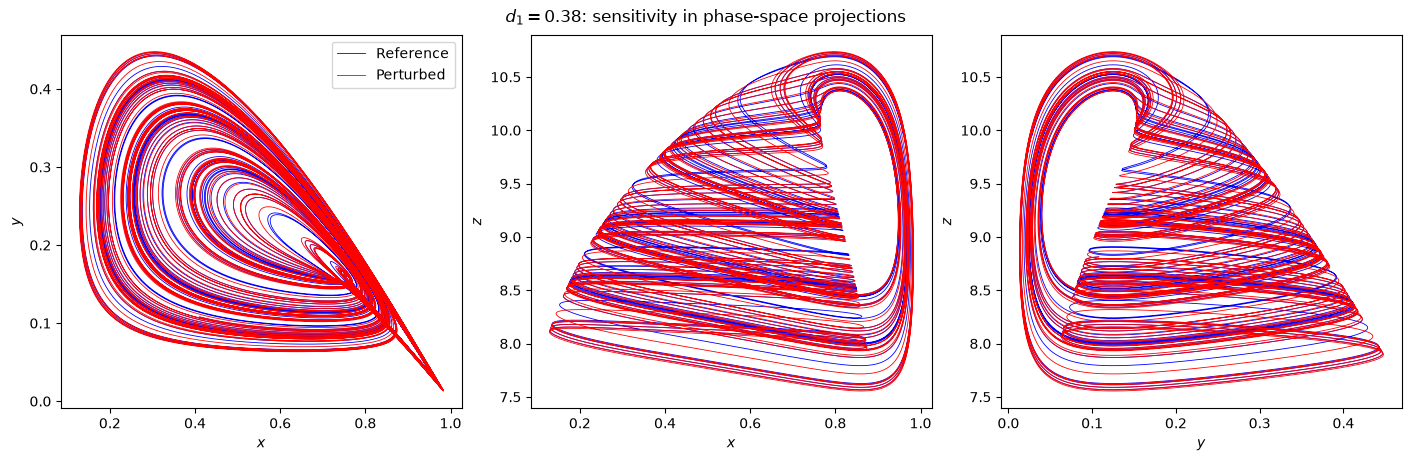

In [28]:
# Nearby trajectories in phase-space projections at d1 = 0.38

fig, axes = plt.subplots(
    1,
    3,
    figsize=(14, 4.5),
    constrained_layout=True
)


# Blue: reference trajectory
# Red: infinitesimally perturbed trajectory

axes[0].plot(
    sensitivity_reference_038[:, 0],
    sensitivity_reference_038[:, 1],
    color="blue",
    linewidth=0.6,
    label="Reference"
)

axes[0].plot(
    sensitivity_perturbed_038[:, 0],
    sensitivity_perturbed_038[:, 1],
    color="red",
    linewidth=0.6,
    label="Perturbed"
)


axes[1].plot(
    sensitivity_reference_038[:, 0],
    sensitivity_reference_038[:, 2],
    color="blue",
    linewidth=0.6
)

axes[1].plot(
    sensitivity_perturbed_038[:, 0],
    sensitivity_perturbed_038[:, 2],
    color="red",
    linewidth=0.6
)


axes[2].plot(
    sensitivity_reference_038[:, 1],
    sensitivity_reference_038[:, 2],
    color="blue",
    linewidth=0.6
)

axes[2].plot(
    sensitivity_perturbed_038[:, 1],
    sensitivity_perturbed_038[:, 2],
    color="red",
    linewidth=0.6
)


axes[0].set_xlabel(
    r"$x$"
)

axes[0].set_ylabel(
    r"$y$"
)


axes[1].set_xlabel(
    r"$x$"
)

axes[1].set_ylabel(
    r"$z$"
)


axes[2].set_xlabel(
    r"$y$"
)

axes[2].set_ylabel(
    r"$z$"
)


axes[0].legend()


fig.suptitle(
    r"$d_1 = 0.38$: sensitivity in phase-space projections"
)


fig.savefig(
    figures_dir
    / "hp_d1_038_sensitivity_projections.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    figures_dir
    / "hp_d1_038_sensitivity_projections.pdf",
    bbox_inches="tight"
)


plt.show()

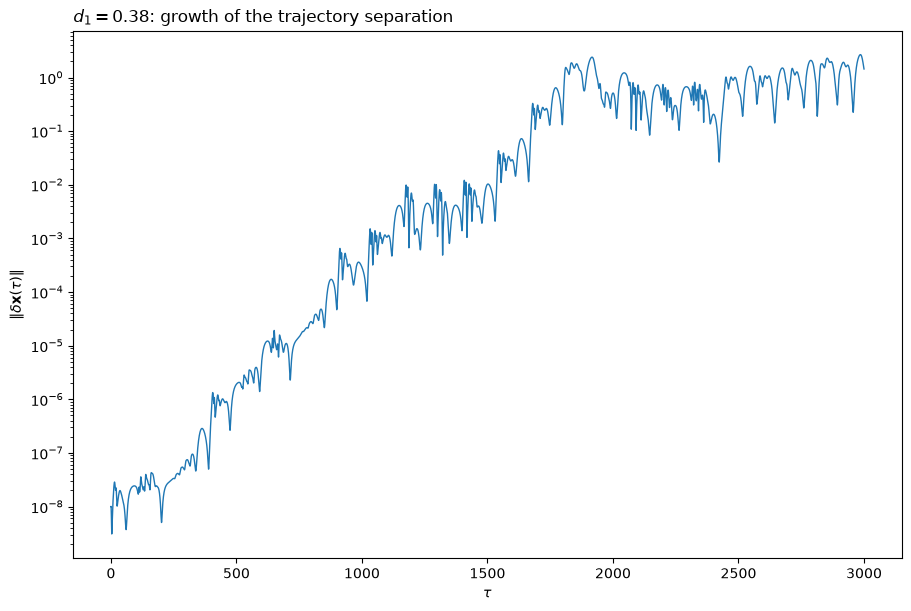

In [29]:
# Logarithmic separation at d1 = 0.38

fig, ax = plt.subplots(
    figsize=(9, 6),
    constrained_layout=True
)


ax.semilogy(
    sensitivity_times_038,
    separation_038,
    linewidth=1.0
)


ax.set_xlabel(
    r"$\tau$"
)

ax.set_ylabel(
    r"$\|\delta \mathbf{x}(\tau)\|$"
)

ax.set_title(
    r"$d_1 = 0.38$: growth of the trajectory separation",
    loc="left"
)


fig.savefig(
    figures_dir
    / "hp_d1_038_sensitivity_separation.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    figures_dir
    / "hp_d1_038_sensitivity_separation.pdf",
    bbox_inches="tight"
)


plt.show()

In [30]:
# Save the attractor and time series in one animation

def save_dynamics_animation(
    times,
    trajectory,
    d1,
    points_per_frame,
    fps,
    filename
):

    n_points = len(
        times
    )


    # Every trajectory point is kept.
    # Frames only control how fast new points appear.

    frame_ends = np.arange(
        1,
        n_points + 1,
        points_per_frame
    )


    if frame_ends[-1] != n_points:

        frame_ends = np.append(
            frame_ends,
            n_points
        )


    # Figure layout

    fig = plt.figure(
        figsize=(13, 7),
        constrained_layout=True
    )

    gs = fig.add_gridspec(
        3,
        2,
        width_ratios=[1.25, 1.0]
    )


    ax_3d = fig.add_subplot(
        gs[:, 0],
        projection="3d"
    )

    ax_x = fig.add_subplot(
        gs[0, 1]
    )

    ax_y = fig.add_subplot(
        gs[1, 1],
        sharex=ax_x
    )

    ax_z = fig.add_subplot(
        gs[2, 1],
        sharex=ax_x
    )


    # Full axis limits stay fixed during the animation

    x = trajectory[:, 0]
    y = trajectory[:, 1]
    z = trajectory[:, 2]


    ax_3d.set_xlim(
        np.min(x),
        np.max(x)
    )

    ax_3d.set_ylim(
        np.min(y),
        np.max(y)
    )

    ax_3d.set_zlim(
        np.min(z),
        np.max(z)
    )

    ax_3d.set_xlabel(
        r"$x$"
    )

    ax_3d.set_ylabel(
        r"$y$"
    )

    ax_3d.set_zlabel(
        r"$z$"
    )

    ax_3d.set_title(
        "Chaotic attractor"
    )


    # Time-series axes

    for ax in (
        ax_x,
        ax_y,
        ax_z
    ):

        ax.set_xlim(
            times[0],
            times[-1]
        )


    ax_x.set_ylim(
        np.min(x),
        np.max(x)
    )

    ax_y.set_ylim(
        np.min(y),
        np.max(y)
    )

    ax_z.set_ylim(
        np.min(z),
        np.max(z)
    )


    ax_x.set_ylabel(
        r"$x(t)$"
    )

    ax_y.set_ylabel(
        r"$y(t)$"
    )

    ax_z.set_ylabel(
        r"$z(t)$"
    )

    ax_z.set_xlabel(
        "Time"
    )


    # Empty lines updated at each frame

    line_3d, = ax_3d.plot(
        [],
        [],
        [],
        linewidth=0.6
    )

    point_3d, = ax_3d.plot(
        [],
        [],
        [],
        marker="o",
        markersize=5
    )


    line_x, = ax_x.plot(
        [],
        [],
        linewidth=0.7
    )

    line_y, = ax_y.plot(
        [],
        [],
        linewidth=0.7
    )

    line_z, = ax_z.plot(
        [],
        [],
        linewidth=0.7
    )


    point_x, = ax_x.plot(
        [],
        [],
        marker="o",
        markersize=4
    )

    point_y, = ax_y.plot(
        [],
        [],
        marker="o",
        markersize=4
    )

    point_z, = ax_z.plot(
        [],
        [],
        marker="o",
        markersize=4
    )


    title = fig.suptitle(
        ""
    )


    def update(frame):

        end = frame_ends[
            frame
        ]


        # Use all points up to the current time

        current_t = times[
            :end
        ]

        current_x = x[
            :end
        ]

        current_y = y[
            :end
        ]

        current_z = z[
            :end
        ]


        line_3d.set_data(
            current_x,
            current_y
        )

        line_3d.set_3d_properties(
            current_z
        )


        point_3d.set_data(
            [x[end - 1]],
            [y[end - 1]]
        )

        point_3d.set_3d_properties(
            [z[end - 1]]
        )


        line_x.set_data(
            current_t,
            current_x
        )

        line_y.set_data(
            current_t,
            current_y
        )

        line_z.set_data(
            current_t,
            current_z
        )


        point_x.set_data(
            [times[end - 1]],
            [x[end - 1]]
        )

        point_y.set_data(
            [times[end - 1]],
            [y[end - 1]]
        )

        point_z.set_data(
            [times[end - 1]],
            [z[end - 1]]
        )


        title.set_text(
            rf"$d_1 = {d1:.2f}$"
            rf"   |   "
            rf"$t = {times[end - 1]:.2f}$"
        )


        return (
            line_3d,
            point_3d,
            line_x,
            point_x,
            line_y,
            point_y,
            line_z,
            point_z,
            title
        )


    animation = FuncAnimation(
        fig,
        update,
        frames=len(frame_ends),
        interval=1000 / fps,
        blit=False
    )


    writer = PillowWriter(
        fps=fps
    )


    print(
        "Trajectory points:",
        n_points
    )

    print(
        "Animation frames:",
        len(frame_ends)
    )

    print(
        "Saving:",
        filename
    )


    animation.save(
        filename,
        writer=writer,
        dpi=100
    )


    plt.close(
        fig
    )


    print(
        "Saved:",
        filename
    )

In [31]:
# Animation at d1 = 0.40

save_dynamics_animation(
    plot_times,
    plot_trajectory_040,
    d1_040,
    animation_points_per_frame,
    animation_fps,
    animation_file_040
)

Trajectory points: 150001
Animation frames: 301
Saving: figures/hp_d1_040_dynamics.gif
Saved: figures/hp_d1_040_dynamics.gif


In [32]:
# Animation at d1 = 0.38

save_dynamics_animation(
    plot_times,
    plot_trajectory_038,
    d1_038,
    animation_points_per_frame,
    animation_fps,
    animation_file_038
)

Trajectory points: 150001
Animation frames: 301
Saving: figures/hp_d1_038_dynamics.gif
Saved: figures/hp_d1_038_dynamics.gif


In [33]:
# Lyapunov spectrum, running exponent, and block values in one run

@njit
def lyapunov_run(
    parameters,
    initial_state,
    dt,
    transient_time,
    alignment_time,
    average_time,
    renormalization_time,
    block_time
):

    state = initial_state.copy()


    # Remove the state transient first

    transient_steps = int(
        round(
            transient_time / dt
        )
    )

    for _ in range(
        transient_steps
    ):

        state = rk4_step(
            state,
            parameters,
            dt
        )


    # Align the tangent directions before collecting exponents

    tangent_matrix = np.eye(3)

    steps_per_renormalization = int(
        round(
            renormalization_time / dt
        )
    )

    alignment_renormalizations = int(
        round(
            alignment_time
            / renormalization_time
        )
    )


    for _ in range(
        alignment_renormalizations
    ):

        for _ in range(
            steps_per_renormalization
        ):

            state, tangent_matrix = rk4_tangent_matrix_step(
                state,
                tangent_matrix,
                parameters,
                dt
            )


        tangent_matrix, _ = gram_schmidt(
            tangent_matrix
        )


    # Averaging starts here.
    # This time is local to the Lyapunov average.

    n_renormalizations = int(
        round(
            average_time
            / renormalization_time
        )
    )

    renormalizations_per_block = int(
        round(
            block_time
            / renormalization_time
        )
    )

    n_blocks = int(
        round(
            average_time
            / block_time
        )
    )


    running_times = np.empty(
        n_renormalizations
    )

    running_spectrum = np.empty(
        (n_renormalizations, 3)
    )


    block_times = np.empty(
        n_blocks
    )

    block_spectrum = np.empty(
        (n_blocks, 3)
    )


    total_log_growth = np.zeros(3)
    block_log_growth = np.zeros(3)

    trace_sum = 0.0
    trace_count = 0

    block_index = 0


    for i in range(
        n_renormalizations
    ):

        for _ in range(
            steps_per_renormalization
        ):

            state, tangent_matrix = rk4_tangent_matrix_step(
                state,
                tangent_matrix,
                parameters,
                dt
            )


            # Keep the divergence along the same trajectory

            jacobian = hp_jacobian(
                state,
                parameters
            )

            trace_sum += (
                jacobian[0, 0]
                + jacobian[1, 1]
                + jacobian[2, 2]
            )

            trace_count += 1


        tangent_matrix, growth = gram_schmidt(
            tangent_matrix
        )


        log_growth = np.log(
            growth
        )


        total_log_growth += log_growth
        block_log_growth += log_growth


        current_time = (
            (i + 1)
            * renormalization_time
        )


        running_times[i] = current_time

        running_spectrum[i] = (
            total_log_growth
            / current_time
        )


        # Keep raw block values for stationarity and errors

        if (
            (i + 1)
            % renormalizations_per_block
            == 0
        ):

            block_times[
                block_index
            ] = current_time

            block_spectrum[
                block_index
            ] = (
                block_log_growth
                / block_time
            )

            block_log_growth[:] = 0.0

            block_index += 1


    mean_trace = (
        trace_sum
        / trace_count
    )


    return (
        running_times,
        running_spectrum,
        block_times,
        block_spectrum,
        mean_trace,
        state
    )

In [34]:
# Lyapunov calculation at d1 = 0.40

(
    lyap_times_040,
    running_spectrum_040,
    block_times_040,
    block_spectrum_040,
    mean_trace_040,
    lyap_final_state_040
) = lyapunov_run(
    parameters_040,
    lyapunov_initial_state,
    dt,
    transient_time,
    alignment_time,
    average_time,
    renormalization_time,
    block_time
)


# Final spectrum from the full average

final_spectrum_040 = running_spectrum_040[-1]

final_lambda1_040 = final_spectrum_040[0]
final_lambda2_040 = final_spectrum_040[1]
final_lambda3_040 = final_spectrum_040[2]


print("d1 = 0.40")
print()

print(
    "Running points:",
    len(lyap_times_040)
)

print(
    "Lyapunov blocks:",
    len(block_times_040)
)

print()

print(
    "Final spectrum:",
    final_spectrum_040
)

print(
    "lambda1:",
    final_lambda1_040
)

print(
    "lambda2:",
    final_lambda2_040
)

print(
    "lambda3:",
    final_lambda3_040
)

print()

print(
    "Spectrum sum:",
    np.sum(final_spectrum_040)
)

print(
    "Mean trace:",
    mean_trace_040
)

print(
    "Trace difference:",
    np.sum(final_spectrum_040)
    - mean_trace_040
)

d1 = 0.40

Running points: 200000
Lyapunov blocks: 80

Final spectrum: [ 7.03934771e-03 -7.41975136e-06 -4.64094990e-01]
lambda1: 0.007039347713410977
lambda2: -7.4197513632001644e-06
lambda3: -0.4640949895901957

Spectrum sum: -0.4570630616281479
Mean trace: -0.4570630717421971
Trace difference: 1.0114049209253295e-08


In [35]:
# Conservative errors and stationarity from the raw blocks

def lyapunov_statistics(
    block_spectrum
):

    n_blocks = block_spectrum.shape[0]

    mean_spectrum = np.mean(
        block_spectrum,
        axis=0
    )


    # Estimate the 95% error with groups of 1, 2, and 4 blocks

    grouping_sizes = np.array([
        1,
        2,
        4
    ])

    grouped_errors = np.empty(
        (len(grouping_sizes), 3)
    )


    for i, group_size in enumerate(
        grouping_sizes
    ):

        n_groups = (
            n_blocks
            // group_size
        )

        grouped = block_spectrum[
            :n_groups * group_size
        ].reshape(
            n_groups,
            group_size,
            3
        ).mean(
            axis=1
        )


        standard_error = (
            np.std(
                grouped,
                axis=0,
                ddof=1
            )
            / np.sqrt(n_groups)
        )


        t_critical = student_t.ppf(
            0.975,
            n_groups - 1
        )


        grouped_errors[i] = (
            t_critical
            * standard_error
        )


    # Keep the most conservative error for each exponent

    errors = np.max(
        grouped_errors,
        axis=0
    )


    # Compare the two halves of the run

    half = (
        n_blocks
        // 2
    )

    first_half = np.mean(
        block_spectrum[:half],
        axis=0
    )

    second_half = np.mean(
        block_spectrum[half:],
        axis=0
    )


    drift = np.abs(
        second_half
        - first_half
    )


    # Flag components whose drift is larger than the global error

    stationary = (
        drift
        <= errors
    )


    return (
        mean_spectrum,
        errors,
        grouped_errors,
        first_half,
        second_half,
        drift,
        stationary
    )


(
    mean_spectrum_040,
    errors_040,
    grouped_errors_040,
    first_half_040,
    second_half_040,
    drift_040,
    stationary_040
) = lyapunov_statistics(
    block_spectrum_040
)


print("d1 = 0.40")
print()

print(
    "Spectrum from blocks:",
    mean_spectrum_040
)

print(
    "Spectrum from running average:",
    final_spectrum_040
)

print(
    "Difference:",
    mean_spectrum_040
    - final_spectrum_040
)

print()

print(
    "95% errors:",
    errors_040
)

print()

print(
    "First half:",
    first_half_040
)

print(
    "Second half:",
    second_half_040
)

print(
    "Drift:",
    drift_040
)

print(
    "Stationary:",
    stationary_040
)

d1 = 0.40

Spectrum from blocks: [ 7.03934771e-03 -7.41975136e-06 -4.64094990e-01]
Spectrum from running average: [ 7.03934771e-03 -7.41975136e-06 -4.64094990e-01]
Difference: [ 4.68375339e-17  1.08420217e-19 -9.54791801e-15]

95% errors: [0.0002559  0.00019418 0.00074409]

First half: [ 7.13719745e-03  6.97067423e-07 -4.64052746e-01]
Second half: [ 6.94149798e-03 -1.55365701e-05 -4.64137233e-01]
Drift: [1.95699471e-04 1.62336376e-05 8.44866364e-05]
Stationary: [ True  True  True]


In [36]:
# Lyapunov calculation at d1 = 0.38

(
    lyap_times_038,
    running_spectrum_038,
    block_times_038,
    block_spectrum_038,
    mean_trace_038,
    lyap_final_state_038
) = lyapunov_run(
    parameters_038,
    lyapunov_initial_state,
    dt,
    transient_time,
    alignment_time,
    average_time,
    renormalization_time,
    block_time
)


# Final spectrum from the full average

final_spectrum_038 = running_spectrum_038[-1]

final_lambda1_038 = final_spectrum_038[0]
final_lambda2_038 = final_spectrum_038[1]
final_lambda3_038 = final_spectrum_038[2]


print("d1 = 0.38")
print()

print(
    "Running points:",
    len(lyap_times_038)
)

print(
    "Lyapunov blocks:",
    len(block_times_038)
)

print()

print(
    "Final spectrum:",
    final_spectrum_038
)

print(
    "lambda1:",
    final_lambda1_038
)

print(
    "lambda2:",
    final_lambda2_038
)

print(
    "lambda3:",
    final_lambda3_038
)

print()

print(
    "Spectrum sum:",
    np.sum(final_spectrum_038)
)

print(
    "Mean trace:",
    mean_trace_038
)

print(
    "Trace difference:",
    np.sum(final_spectrum_038)
    - mean_trace_038
)

d1 = 0.38

Running points: 200000
Lyapunov blocks: 80

Final spectrum: [ 1.03880433e-02 -1.73609349e-07 -4.65574547e-01]
lambda1: 0.010388043268544618
lambda2: -1.7360934922856895e-07
lambda3: -0.4655745467339952

Spectrum sum: -0.45518667707479976
Mean trace: -0.45518667480730696
Trace difference: -2.2674928046306775e-09


In [37]:
# Conservative errors and stationarity at d1 = 0.38

(
    mean_spectrum_038,
    errors_038,
    grouped_errors_038,
    first_half_038,
    second_half_038,
    drift_038,
    stationary_038
) = lyapunov_statistics(
    block_spectrum_038
)


print("d1 = 0.38")
print()

print(
    "Spectrum from blocks:",
    mean_spectrum_038
)

print(
    "Spectrum from running average:",
    final_spectrum_038
)

print(
    "Difference:",
    mean_spectrum_038
    - final_spectrum_038
)

print()

print(
    "95% errors:",
    errors_038
)

print()

print(
    "First half:",
    first_half_038
)

print(
    "Second half:",
    second_half_038
)

print(
    "Drift:",
    drift_038
)

print(
    "Stationary:",
    stationary_038
)

d1 = 0.38

Spectrum from blocks: [ 1.03880433e-02 -1.73609349e-07 -4.65574547e-01]
Spectrum from running average: [ 1.03880433e-02 -1.73609349e-07 -4.65574547e-01]
Difference: [-6.76542156e-17  1.17975808e-19  3.60822483e-15]

95% errors: [0.00022803 0.0001567  0.00083536]

First half: [ 1.04207334e-02  1.18604465e-05 -4.65405992e-01]
Second half: [ 1.03553532e-02 -1.22076652e-05 -4.65743102e-01]
Drift: [6.53802317e-05 2.40681117e-05 3.37110195e-04]
Stationary: [ True  True  True]


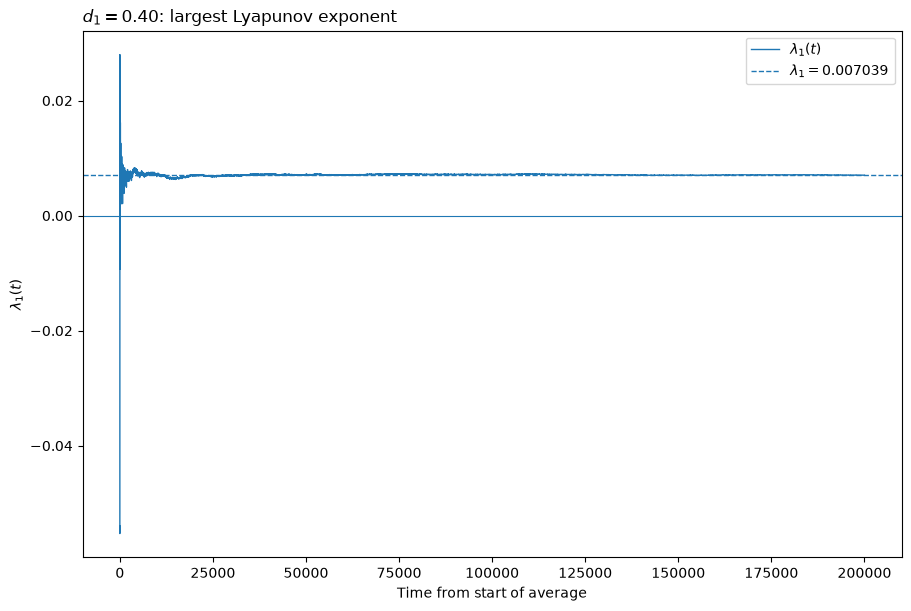

In [38]:
# Running largest Lyapunov exponent at d1 = 0.40

fig, ax = plt.subplots(
    figsize=(9, 6),
    constrained_layout=True
)


ax.plot(
    lyap_times_040,
    running_spectrum_040[:, 0],
    linewidth=1.0,
    label=r"$\lambda_1(t)$"
)


# Final estimate from the full average

ax.axhline(
    final_lambda1_040,
    linestyle="--",
    linewidth=1.0,
    label=(
        rf"$\lambda_1 = "
        rf"{final_lambda1_040:.6f}$"
    )
)


ax.axhline(
    0.0,
    linewidth=0.8
)


ax.set_xlabel(
    "Time from start of average"
)

ax.set_ylabel(
    r"$\lambda_1(t)$"
)

ax.set_title(
    r"$d_1 = 0.40$: largest Lyapunov exponent",
    loc="left"
)

ax.legend()


fig.savefig(
    figures_dir
    / "hp_d1_040_running_lyapunov.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    figures_dir
    / "hp_d1_040_running_lyapunov.pdf",
    bbox_inches="tight"
)


plt.show()

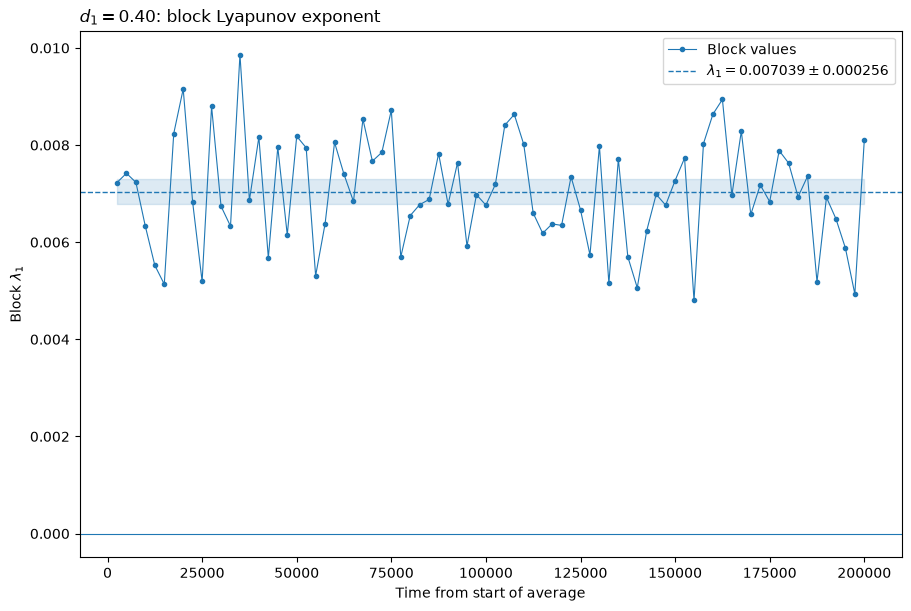

In [39]:
# Block largest Lyapunov exponent at d1 = 0.40

fig, ax = plt.subplots(
    figsize=(9, 6),
    constrained_layout=True
)


line, = ax.plot(
    block_times_040,
    block_spectrum_040[:, 0],
    marker="o",
    markersize=3,
    linewidth=0.8,
    label="Block values"
)


# The shaded band is the global 95% uncertainty

ax.axhline(
    final_lambda1_040,
    color=line.get_color(),
    linestyle="--",
    linewidth=1.0,
    label=(
        rf"$\lambda_1 = "
        rf"{final_lambda1_040:.6f}"
        rf"\pm{errors_040[0]:.6f}$"
    )
)


ax.fill_between(
    block_times_040,
    final_lambda1_040 - errors_040[0],
    final_lambda1_040 + errors_040[0],
    color=line.get_color(),
    alpha=0.15
)


ax.axhline(
    0.0,
    linewidth=0.8
)


ax.set_xlabel(
    "Time from start of average"
)

ax.set_ylabel(
    r"Block $\lambda_1$"
)

ax.set_title(
    r"$d_1 = 0.40$: block Lyapunov exponent",
    loc="left"
)

ax.legend()


fig.savefig(
    figures_dir
    / "hp_d1_040_block_lyapunov.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    figures_dir
    / "hp_d1_040_block_lyapunov.pdf",
    bbox_inches="tight"
)


plt.show()

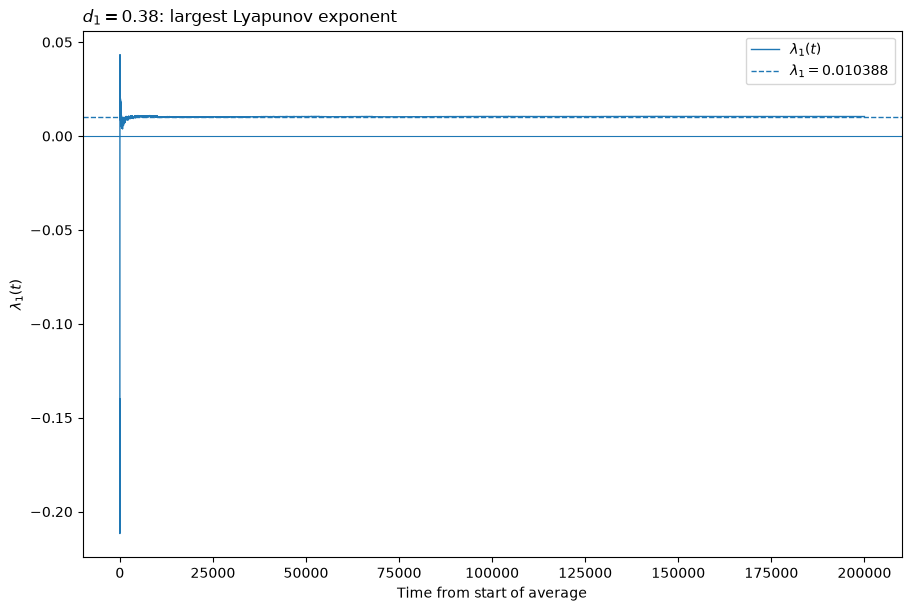

In [40]:
# Running largest Lyapunov exponent at d1 = 0.38

fig, ax = plt.subplots(
    figsize=(9, 6),
    constrained_layout=True
)


ax.plot(
    lyap_times_038,
    running_spectrum_038[:, 0],
    linewidth=1.0,
    label=r"$\lambda_1(t)$"
)


# Final estimate from the full average

ax.axhline(
    final_lambda1_038,
    linestyle="--",
    linewidth=1.0,
    label=(
        rf"$\lambda_1 = "
        rf"{final_lambda1_038:.6f}$"
    )
)


ax.axhline(
    0.0,
    linewidth=0.8
)


ax.set_xlabel(
    "Time from start of average"
)

ax.set_ylabel(
    r"$\lambda_1(t)$"
)

ax.set_title(
    r"$d_1 = 0.38$: largest Lyapunov exponent",
    loc="left"
)

ax.legend()


fig.savefig(
    figures_dir
    / "hp_d1_038_running_lyapunov.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    figures_dir
    / "hp_d1_038_running_lyapunov.pdf",
    bbox_inches="tight"
)


plt.show()

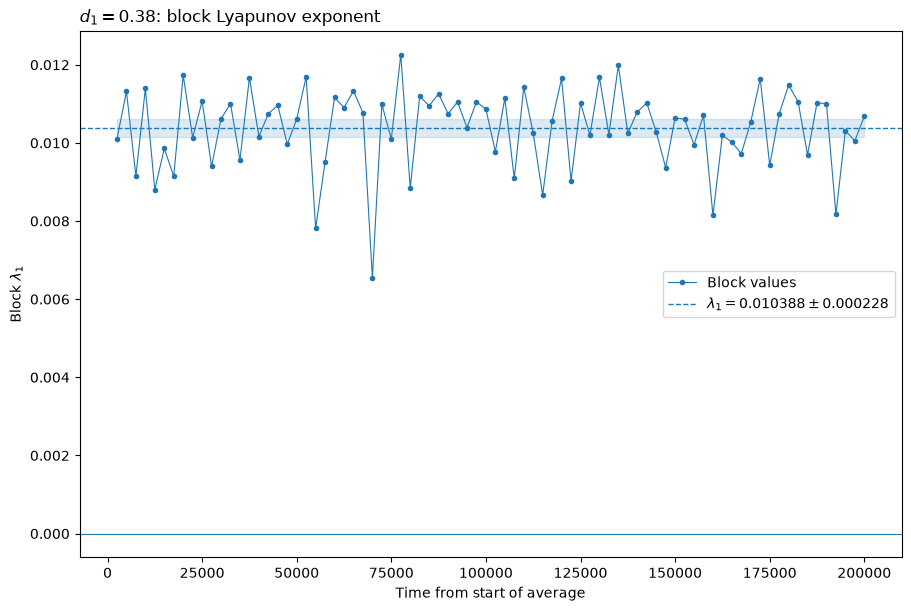

In [41]:
# Block largest Lyapunov exponent at d1 = 0.38

fig, ax = plt.subplots(
    figsize=(9, 6),
    constrained_layout=True
)


line, = ax.plot(
    block_times_038,
    block_spectrum_038[:, 0],
    marker="o",
    markersize=3,
    linewidth=0.8,
    label="Block values"
)


# The shaded band is the global 95% uncertainty

ax.axhline(
    final_lambda1_038,
    color=line.get_color(),
    linestyle="--",
    linewidth=1.0,
    label=(
        rf"$\lambda_1 = "
        rf"{final_lambda1_038:.6f}"
        rf"\pm{errors_038[0]:.6f}$"
    )
)


ax.fill_between(
    block_times_038,
    final_lambda1_038 - errors_038[0],
    final_lambda1_038 + errors_038[0],
    color=line.get_color(),
    alpha=0.15
)


ax.axhline(
    0.0,
    linewidth=0.8
)


ax.set_xlabel(
    "Time from start of average"
)

ax.set_ylabel(
    r"Block $\lambda_1$"
)

ax.set_title(
    r"$d_1 = 0.38$: block Lyapunov exponent",
    loc="left"
)

ax.legend()


fig.savefig(
    figures_dir
    / "hp_d1_038_block_lyapunov.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    figures_dir
    / "hp_d1_038_block_lyapunov.pdf",
    bbox_inches="tight"
)


plt.show()

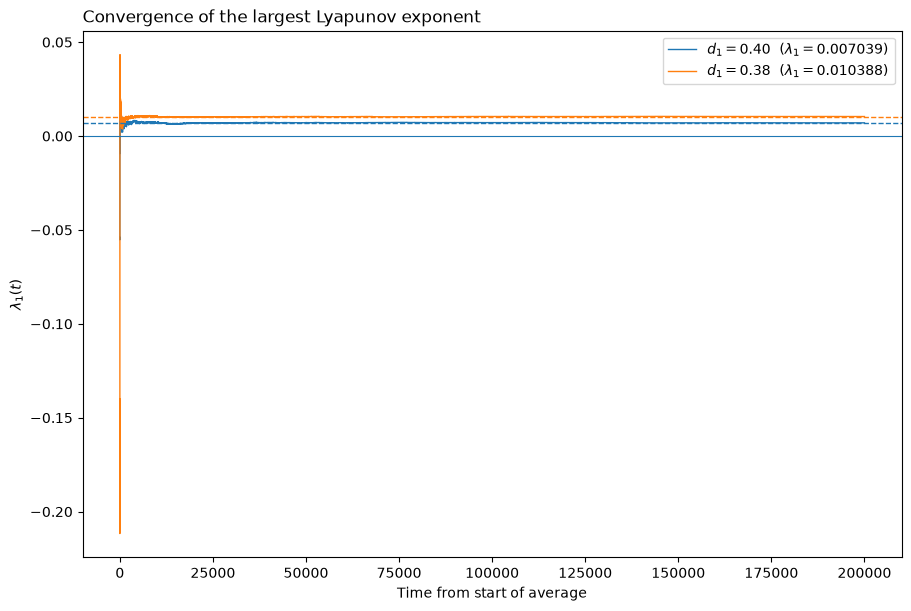

In [42]:
# Compare the running largest Lyapunov exponents

fig, ax = plt.subplots(
    figsize=(9, 6),
    constrained_layout=True
)


line_040, = ax.plot(
    lyap_times_040,
    running_spectrum_040[:, 0],
    linewidth=1.0,
    label=(
        rf"$d_1 = 0.40$"
        rf"  ($\lambda_1 = {final_lambda1_040:.6f}$)"
    )
)

line_038, = ax.plot(
    lyap_times_038,
    running_spectrum_038[:, 0],
    linewidth=1.0,
    label=(
        rf"$d_1 = 0.38$"
        rf"  ($\lambda_1 = {final_lambda1_038:.6f}$)"
    )
)


# Match each final-value line to its running curve

ax.axhline(
    final_lambda1_040,
    color=line_040.get_color(),
    linestyle="--",
    linewidth=1.0
)

ax.axhline(
    final_lambda1_038,
    color=line_038.get_color(),
    linestyle="--",
    linewidth=1.0
)


ax.axhline(
    0.0,
    linewidth=0.8
)


ax.set_xlabel(
    "Time from start of average"
)

ax.set_ylabel(
    r"$\lambda_1(t)$"
)

ax.set_title(
    "Convergence of the largest Lyapunov exponent",
    loc="left"
)

ax.legend()


fig.savefig(
    figures_dir
    / "hp_running_lyapunov_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    figures_dir
    / "hp_running_lyapunov_comparison.pdf",
    bbox_inches="tight"
)


plt.show()

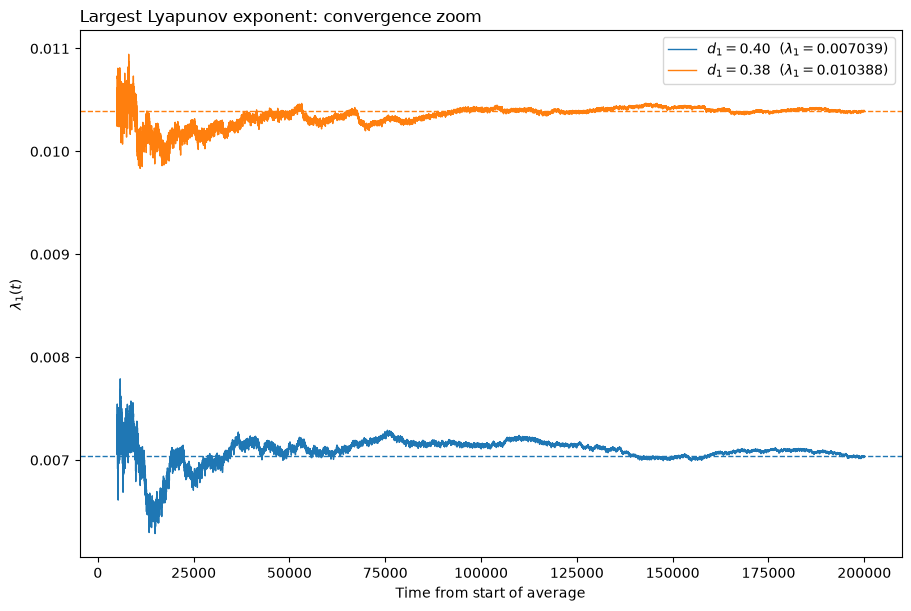

In [43]:
# Zoom of the running Lyapunov convergence

zoom_start = 5000.0


mask_040_zoom = (
    lyap_times_040
    >= zoom_start
)

mask_038_zoom = (
    lyap_times_038
    >= zoom_start
)


fig, ax = plt.subplots(
    figsize=(9, 6),
    constrained_layout=True
)


line_040, = ax.plot(
    lyap_times_040[mask_040_zoom],
    running_spectrum_040[
        mask_040_zoom,
        0
    ],
    linewidth=1.0,
    label=(
        rf"$d_1 = 0.40$"
        rf"  ($\lambda_1 = {final_lambda1_040:.6f}$)"
    )
)

line_038, = ax.plot(
    lyap_times_038[mask_038_zoom],
    running_spectrum_038[
        mask_038_zoom,
        0
    ],
    linewidth=1.0,
    label=(
        rf"$d_1 = 0.38$"
        rf"  ($\lambda_1 = {final_lambda1_038:.6f}$)"
    )
)


# Keep the reference lines in the same colors

ax.axhline(
    final_lambda1_040,
    color=line_040.get_color(),
    linestyle="--",
    linewidth=1.0
)

ax.axhline(
    final_lambda1_038,
    color=line_038.get_color(),
    linestyle="--",
    linewidth=1.0
)


ax.set_xlabel(
    "Time from start of average"
)

ax.set_ylabel(
    r"$\lambda_1(t)$"
)

ax.set_title(
    "Largest Lyapunov exponent: convergence zoom",
    loc="left"
)

ax.legend()


fig.savefig(
    figures_dir
    / "hp_running_lyapunov_comparison_zoom.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    figures_dir
    / "hp_running_lyapunov_comparison_zoom.pdf",
    bbox_inches="tight"
)


plt.show()

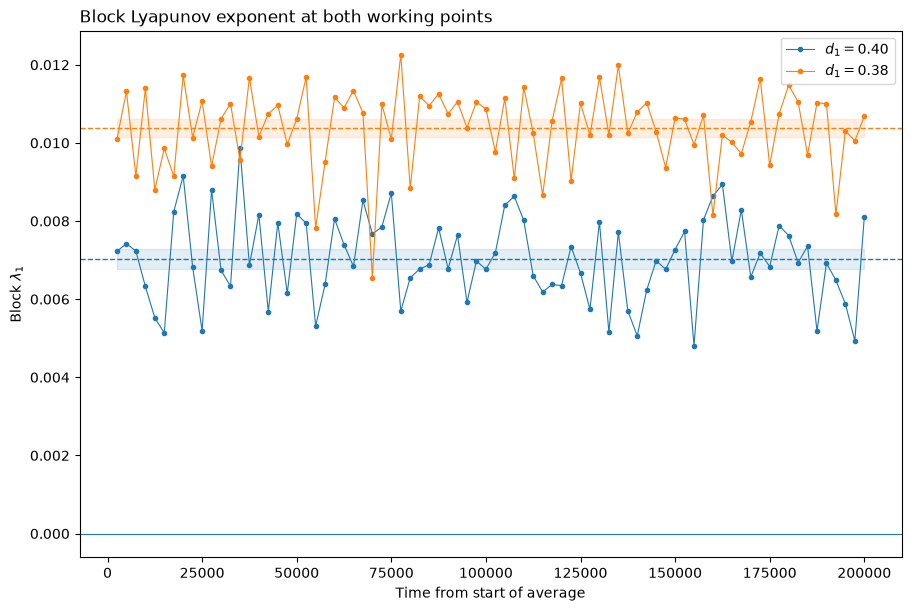

In [44]:
# Compare the block largest Lyapunov exponents

fig, ax = plt.subplots(
    figsize=(9, 6),
    constrained_layout=True
)


line_040, = ax.plot(
    block_times_040,
    block_spectrum_040[:, 0],
    marker="o",
    markersize=3,
    linewidth=0.8,
    label=r"$d_1 = 0.40$"
)

line_038, = ax.plot(
    block_times_038,
    block_spectrum_038[:, 0],
    marker="o",
    markersize=3,
    linewidth=0.8,
    label=r"$d_1 = 0.38$"
)


# Match each mean line and uncertainty band to its block curve

ax.axhline(
    final_lambda1_040,
    color=line_040.get_color(),
    linestyle="--",
    linewidth=1.0
)

ax.axhline(
    final_lambda1_038,
    color=line_038.get_color(),
    linestyle="--",
    linewidth=1.0
)


ax.fill_between(
    block_times_040,
    final_lambda1_040 - errors_040[0],
    final_lambda1_040 + errors_040[0],
    color=line_040.get_color(),
    alpha=0.12
)

ax.fill_between(
    block_times_038,
    final_lambda1_038 - errors_038[0],
    final_lambda1_038 + errors_038[0],
    color=line_038.get_color(),
    alpha=0.12
)


ax.axhline(
    0.0,
    linewidth=0.8
)


ax.set_xlabel(
    "Time from start of average"
)

ax.set_ylabel(
    r"Block $\lambda_1$"
)

ax.set_title(
    "Block Lyapunov exponent at both working points",
    loc="left"
)

ax.legend()


fig.savefig(
    figures_dir
    / "hp_block_lyapunov_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    figures_dir
    / "hp_block_lyapunov_comparison.pdf",
    bbox_inches="tight"
)


plt.show()

In [45]:
# Save the numerical results that still exist only in memory


# ------------------------------------------------------------
# Running Lyapunov spectra
# ------------------------------------------------------------

np.savez(
    data_dir / "hp_d1_040_lyapunov_running.npz",
    time=lyap_times_040,
    spectrum=running_spectrum_040,
    final_state=lyap_final_state_040,
    mean_trace=mean_trace_040
)

np.savez(
    data_dir / "hp_d1_038_lyapunov_running.npz",
    time=lyap_times_038,
    spectrum=running_spectrum_038,
    final_state=lyap_final_state_038,
    mean_trace=mean_trace_038
)


# ------------------------------------------------------------
# Raw Lyapunov blocks
# ------------------------------------------------------------

block_data_040 = np.column_stack([
    block_times_040,
    block_spectrum_040
])

block_data_038 = np.column_stack([
    block_times_038,
    block_spectrum_038
])


np.savetxt(
    data_dir / "hp_d1_040_lyapunov_blocks.csv",
    block_data_040,
    delimiter=",",
    header="time,lambda1,lambda2,lambda3",
    comments="# ",
    fmt="%.16e"
)

np.savetxt(
    data_dir / "hp_d1_038_lyapunov_blocks.csv",
    block_data_038,
    delimiter=",",
    header="time,lambda1,lambda2,lambda3",
    comments="# ",
    fmt="%.16e"
)


# ------------------------------------------------------------
# Errors from grouped blocks
# ------------------------------------------------------------

grouping_sizes = np.array([
    1,
    2,
    4
])


grouped_error_data_040 = np.column_stack([
    grouping_sizes,
    grouped_errors_040
])

grouped_error_data_038 = np.column_stack([
    grouping_sizes,
    grouped_errors_038
])


np.savetxt(
    data_dir / "hp_d1_040_lyapunov_grouped_errors.csv",
    grouped_error_data_040,
    delimiter=",",
    header="group_size,error_lambda1,error_lambda2,error_lambda3",
    comments="# ",
    fmt="%.16e"
)

np.savetxt(
    data_dir / "hp_d1_038_lyapunov_grouped_errors.csv",
    grouped_error_data_038,
    delimiter=",",
    header="group_size,error_lambda1,error_lambda2,error_lambda3",
    comments="# ",
    fmt="%.16e"
)


# ------------------------------------------------------------
# Sensitivity data
# ------------------------------------------------------------

np.savez(
    data_dir / "hp_d1_040_sensitivity.npz",
    time=sensitivity_times_040,
    reference=sensitivity_reference_040,
    perturbed=sensitivity_perturbed_040,
    separation=separation_040
)

np.savez(
    data_dir / "hp_d1_038_sensitivity.npz",
    time=sensitivity_times_038,
    reference=sensitivity_reference_038,
    perturbed=sensitivity_perturbed_038,
    separation=separation_038
)


# ------------------------------------------------------------
# Final Lyapunov summary
# ------------------------------------------------------------

summary_header = (
    "d1,"
    "lambda1,error1,"
    "lambda2,error2,"
    "lambda3,error3,"
    "mean_trace,trace_difference,"
    "first_half_lambda1,first_half_lambda2,first_half_lambda3,"
    "second_half_lambda1,second_half_lambda2,second_half_lambda3,"
    "drift_lambda1,drift_lambda2,drift_lambda3,"
    "stationary_lambda1,stationary_lambda2,stationary_lambda3"
)


summary_040 = np.concatenate([
    np.array([d1_040]),
    final_spectrum_040[[0]],
    errors_040[[0]],
    final_spectrum_040[[1]],
    errors_040[[1]],
    final_spectrum_040[[2]],
    errors_040[[2]],
    np.array([
        mean_trace_040,
        np.sum(final_spectrum_040) - mean_trace_040
    ]),
    first_half_040,
    second_half_040,
    drift_040,
    stationary_040.astype(float)
])


summary_038 = np.concatenate([
    np.array([d1_038]),
    final_spectrum_038[[0]],
    errors_038[[0]],
    final_spectrum_038[[1]],
    errors_038[[1]],
    final_spectrum_038[[2]],
    errors_038[[2]],
    np.array([
        mean_trace_038,
        np.sum(final_spectrum_038) - mean_trace_038
    ]),
    first_half_038,
    second_half_038,
    drift_038,
    stationary_038.astype(float)
])


summary = np.vstack([
    summary_040,
    summary_038
])


np.savetxt(
    data_dir / "hp_lyapunov_summary.csv",
    summary,
    delimiter=",",
    header=summary_header,
    comments="# ",
    fmt="%.16e"
)


print("Numerical data saved.")
print()

print(
    "Full trajectories:",
    trajectory_file_040.name,
    trajectory_file_038.name
)

print(
    "Lyapunov running files:",
    "hp_d1_040_lyapunov_running.npz,",
    "hp_d1_038_lyapunov_running.npz"
)

print(
    "Lyapunov block files:",
    "hp_d1_040_lyapunov_blocks.csv,",
    "hp_d1_038_lyapunov_blocks.csv"
)

print(
    "Sensitivity files:",
    "hp_d1_040_sensitivity.npz,",
    "hp_d1_038_sensitivity.npz"
)

print(
    "Summary:",
    "hp_lyapunov_summary.csv"
)

Numerical data saved.

Full trajectories: hp_d1_040_full_trajectory.npy hp_d1_038_full_trajectory.npy
Lyapunov running files: hp_d1_040_lyapunov_running.npz, hp_d1_038_lyapunov_running.npz
Lyapunov block files: hp_d1_040_lyapunov_blocks.csv, hp_d1_038_lyapunov_blocks.csv
Sensitivity files: hp_d1_040_sensitivity.npz, hp_d1_038_sensitivity.npz
Summary: hp_lyapunov_summary.csv


In [46]:
# Final audit of the isolated-dynamics notebook

print("FINAL ISOLATED-DYNAMICS AUDIT")
print("=" * 70)
print()


# ------------------------------------------------------------
# Numerical checks
# ------------------------------------------------------------

for (
    label,
    trajectory,
    final_spectrum,
    errors,
    mean_trace,
    stationary
) in [

    (
        "d1 = 0.40",
        trajectory_040,
        final_spectrum_040,
        errors_040,
        mean_trace_040,
        stationary_040
    ),

    (
        "d1 = 0.38",
        trajectory_038,
        final_spectrum_038,
        errors_038,
        mean_trace_038,
        stationary_038
    )
]:

    trace_difference = (
        np.sum(final_spectrum)
        - mean_trace
    )

    lambda2_zero = (
        abs(final_spectrum[1])
        <= errors[1]
    )


    print(label)

    print(
        "trajectory shape:",
        trajectory.shape
    )

    print(
        "Lyapunov spectrum:",
        final_spectrum
    )

    print(
        "95% errors:",
        errors
    )

    print(
        "lambda1 positive:",
        bool(
            final_spectrum[0] > 0.0
        )
    )

    print(
        "lambda2 compatible with zero:",
        bool(
            lambda2_zero
        )
    )

    print(
        "lambda3 negative:",
        bool(
            final_spectrum[2] < 0.0
        )
    )

    print(
        "trace difference:",
        f"{trace_difference:.3e}"
    )

    print(
        "stationary:",
        stationary
    )

    print()


# ------------------------------------------------------------
# Expected data files
# ------------------------------------------------------------

expected_data_files = [

    "hp_d1_040_full_trajectory.npy",
    "hp_d1_038_full_trajectory.npy",

    "hp_d1_040_lyapunov_running.npz",
    "hp_d1_038_lyapunov_running.npz",

    "hp_d1_040_lyapunov_blocks.csv",
    "hp_d1_038_lyapunov_blocks.csv",

    "hp_d1_040_lyapunov_grouped_errors.csv",
    "hp_d1_038_lyapunov_grouped_errors.csv",

    "hp_d1_040_sensitivity.npz",
    "hp_d1_038_sensitivity.npz",

    "hp_lyapunov_summary.csv"
]


# ------------------------------------------------------------
# Expected static figures
# ------------------------------------------------------------

figure_names = [

    "hp_d1_040_time_series",
    "hp_d1_038_time_series",

    "hp_d1_040_attractor_3d",
    "hp_d1_038_attractor_3d",

    "hp_d1_040_projections",
    "hp_d1_038_projections",

    "hp_d1_040_sensitivity_time_series",
    "hp_d1_038_sensitivity_time_series",

    "hp_d1_040_sensitivity_attractor_3d",
    "hp_d1_038_sensitivity_attractor_3d",

    "hp_d1_040_sensitivity_projections",
    "hp_d1_038_sensitivity_projections",

    "hp_d1_040_sensitivity_separation",
    "hp_d1_038_sensitivity_separation",

    "hp_d1_040_running_lyapunov",
    "hp_d1_038_running_lyapunov",

    "hp_d1_040_block_lyapunov",
    "hp_d1_038_block_lyapunov",

    "hp_running_lyapunov_comparison",
    "hp_running_lyapunov_comparison_zoom",

    "hp_block_lyapunov_comparison"
]


expected_figure_files = []

for name in figure_names:

    expected_figure_files.append(
        name + ".png"
    )

    expected_figure_files.append(
        name + ".pdf"
    )


# GIF files

expected_gif_files = [

    "hp_d1_040_dynamics.gif",
    "hp_d1_038_dynamics.gif"
]


# ------------------------------------------------------------
# Check files
# ------------------------------------------------------------

print("DATA FILES")
print("=" * 70)

all_data_ok = True

for filename in expected_data_files:

    path = data_dir / filename

    exists = path.exists()

    print(
        f"{'OK' if exists else 'MISSING':7s}",
        filename
    )

    if not exists:
        all_data_ok = False


print()
print("FIGURE FILES")
print("=" * 70)

all_figures_ok = True

for filename in expected_figure_files:

    path = figures_dir / filename

    exists = path.exists()

    print(
        f"{'OK' if exists else 'MISSING':7s}",
        filename
    )

    if not exists:
        all_figures_ok = False


print()
print("ANIMATIONS")
print("=" * 70)

all_gifs_ok = True

for filename in expected_gif_files:

    path = figures_dir / filename

    exists = path.exists()

    print(
        f"{'OK' if exists else 'MISSING':7s}",
        filename
    )

    if not exists:
        all_gifs_ok = False


# ------------------------------------------------------------
# Final status
# ------------------------------------------------------------

numerics_ok = (

    final_lambda1_040 > 0.0
    and final_lambda1_038 > 0.0

    and abs(final_lambda2_040) <= errors_040[1]
    and abs(final_lambda2_038) <= errors_038[1]

    and final_lambda3_040 < 0.0
    and final_lambda3_038 < 0.0

    and np.all(stationary_040)
    and np.all(stationary_038)

    and abs(
        np.sum(final_spectrum_040)
        - mean_trace_040
    ) < 1.0e-6

    and abs(
        np.sum(final_spectrum_038)
        - mean_trace_038
    ) < 1.0e-6
)


print()
print("=" * 70)

print(
    "Numerical checks passed:",
    numerics_ok
)

print(
    "All data files found:",
    all_data_ok
)

print(
    "All static figures found:",
    all_figures_ok
)

print(
    "All animations found:",
    all_gifs_ok
)

print()

print(
    "ISOLATED DYNAMICS COMPLETE:",
    (
        numerics_ok
        and all_data_ok
        and all_figures_ok
        and all_gifs_ok
    )
)

FINAL ISOLATED-DYNAMICS AUDIT

d1 = 0.40
trajectory shape: (20000001, 3)
Lyapunov spectrum: [ 7.03934771e-03 -7.41975136e-06 -4.64094990e-01]
95% errors: [0.0002559  0.00019418 0.00074409]
lambda1 positive: True
lambda2 compatible with zero: True
lambda3 negative: True
trace difference: 1.011e-08
stationary: [ True  True  True]

d1 = 0.38
trajectory shape: (20000001, 3)
Lyapunov spectrum: [ 1.03880433e-02 -1.73609349e-07 -4.65574547e-01]
95% errors: [0.00022803 0.0001567  0.00083536]
lambda1 positive: True
lambda2 compatible with zero: True
lambda3 negative: True
trace difference: -2.267e-09
stationary: [ True  True  True]

DATA FILES
OK      hp_d1_040_full_trajectory.npy
OK      hp_d1_038_full_trajectory.npy
OK      hp_d1_040_lyapunov_running.npz
OK      hp_d1_038_lyapunov_running.npz
OK      hp_d1_040_lyapunov_blocks.csv
OK      hp_d1_038_lyapunov_blocks.csv
OK      hp_d1_040_lyapunov_grouped_errors.csv
OK      hp_d1_038_lyapunov_grouped_errors.csv
OK      hp_d1_040_sensitivity.npz
O